# Exploratory Data Analysis (EDA) — plantilla reutilizable

Plantilla genérica para explorar datasets de **clasificación, regresión o análisis no supervisado**. Detecta tipos de variables, revisa calidad de datos y genera estadísticas y gráficos de forma automática.

## Cómo utilizarla

1. Modificá únicamente la sección **Configuración** (principalmente `DATA_PATH` y, si corresponde, `TARGET`).
2. Ejecutá la notebook de arriba hacia abajo.
3. Revisá las advertencias y los gráficos antes de decidir cómo limpiar o transformar los datos.

> **Importante:** esta notebook es exploratoria. No elimina filas ni columnas, no imputa valores, no codifica categorías y no escala variables. Las conversiones de fechas y números detectadas automáticamente se realizan solamente en una copia auxiliar (`analysis_df`); `df_original` conserva los datos cargados.

La cantidad de gráficos está limitada mediante parámetros configurables para que la plantilla también sea práctica en datasets anchos.

## 1. Imports y configuración

En esta sección se definen las rutas, la variable objetivo y los límites de visualización. Si no hay una variable objetivo, dejá `TARGET = None`.

In [112]:
from pathlib import Path
from itertools import combinations
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown

# -----------------------------
# Configuración del dataset
# -----------------------------
DATA_PATH = Path("Dataset/Telco/Telco-Customer-Churn.csv")  # Cambiar por la ruta del archivo
TARGET = 'Churn'                 # Ejemplo: "Churn". Usar None si no hay target.
SEPARATOR = ","               # Separador del CSV

# -----------------------------
# Configuración del análisis
# -----------------------------
RANDOM_STATE = 42
MAX_CATEGORIES = 15           # Categorías máximas por gráfico
MAX_SAMPLE = 5_000            # Muestra máxima para gráficos costosos
MAX_PAIR_PLOTS = 20           # Scatterplots numérica vs. numérica
MAX_BIVARIATE_PLOTS = 30      # Límite total de gráficos bivariados
MAX_CORR_FEATURES = 30        # Variables máximas en los heatmaps de correlación
MAX_DATETIME_PLOTS = 12       # Relaciones temporales máximas
DATETIME_PARSE_THRESHOLD = 0.80
NUMERIC_PARSE_THRESHOLD = 0.95
PLOT_STYLE = "whitegrid"
FIGURE_DPI = 110

# Para la clasificación automática del target numérico:
TARGET_CLASSIFICATION_MAX_CLASSES = 15

sns.set_theme(style=PLOT_STYLE)
plt.rcParams["figure.dpi"] = FIGURE_DPI
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

print("Configuración cargada.")

Configuración cargada.


## 2. Carga de datos

La carga está preparada para CSV. Para Excel o Parquet, reemplazá `pd.read_csv` por `pd.read_excel` o `pd.read_parquet`, respectivamente.

In [113]:
def load_dataset(path, separator=","):
    """Carga un archivo CSV y devuelve un DataFrame."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            f"No se encontró el archivo: {path.resolve()}\n"
            "Revisá DATA_PATH en la sección de configuración."
        )
    return pd.read_csv(path, sep=separator)


df_original = load_dataset(DATA_PATH, SEPARATOR)
df = df_original.copy(deep=True)

if df.empty:
    raise ValueError("El dataset no contiene filas.")
if df.shape[1] == 0:
    raise ValueError("El dataset no contiene columnas.")
if TARGET is not None and TARGET not in df.columns:
    raise KeyError(f"TARGET='{TARGET}' no existe en el dataset.")

print(f"Dataset cargado correctamente: {df.shape[0]:,} filas × {df.shape[1]:,} columnas")

Dataset cargado correctamente: 7,043 filas × 21 columnas


In [105]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes


In [114]:
columns_to_drop = ['customerID'] #Agregar columnas a dropear segun el caso
df = df.drop(columns=columns_to_drop)


## 3. Exploración inicial

Primero se observa la estructura general, las primeras filas, las estadísticas descriptivas y los tipos de datos. Estas salidas permiten detectar rápidamente errores de carga o columnas inesperadas.

In [115]:
print("DIMENSIONES DEL DATASET")
print(f"Filas:    {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]:,}")

print("\nPRIMERAS FILAS")
display(df.head())

print("\nMUESTRA ALEATORIA")
display(df.sample(n=min(5, len(df)), random_state=RANDOM_STATE))

print("\nINFORMACIÓN GENERAL")
df.info()

print("\nESTADÍSTICAS DESCRIPTIVAS — NUMÉRICAS")
display(df.describe(include=[np.number]).T)

print("\nESTADÍSTICAS DESCRIPTIVAS — CATEGÓRICAS")
cat_desc_cols = [
    col for col in df.columns
    if (pd.api.types.is_object_dtype(df[col])
        or isinstance(df[col].dtype, pd.CategoricalDtype)
        or pd.api.types.is_bool_dtype(df[col]))
]
if cat_desc_cols:
    display(df[cat_desc_cols].describe().T)
else:
    print("No se detectaron columnas categóricas en los tipos originales.")

DIMENSIONES DEL DATASET
Filas:    7,043
Columnas: 20

PRIMERAS FILAS


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes



MUESTRA ALEATORIA


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,Female,0,Yes,No,1,No,No phone service,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,24.800,24.8,Yes
2715,Male,0,No,No,41,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.250,996.45,No
3825,Female,0,Yes,Yes,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.350,1031.7,No
1807,Female,0,No,No,1,Yes,No,Fiber optic,No,No,Yes,No,No,No,Month-to-month,No,Electronic check,76.350,76.35,Yes
132,Male,0,No,No,67,Yes,No,DSL,No,No,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.550,3260.1,No



INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     704

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,"7,043.000",0.162,0.369,0.000,0.000,0.000,0.000,1.000
tenure,"7,043.000",32.371,24.559,0.000,9.000,29.000,55.000,72.000
MonthlyCharges,"7,043.000",64.762,30.090,18.250,35.500,70.350,89.850,118.750



ESTADÍSTICAS DESCRIPTIVAS — CATEGÓRICAS


,count,unique,top,freq
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095
TechSupport,7043,3,No,3473


In [74]:
# Perfil básico por columna
profile_rows = []
for col in df.columns:
    series = df[col]
    try:
        n_unique = series.nunique(dropna=True)
    except TypeError:
        n_unique = series.dropna().astype(str).nunique()

    profile_rows.append({
        "column": col,
        "dtype": str(series.dtype),
        "missing_count": int(series.isna().sum()),
        "missing_pct": 100 * series.isna().mean(),
        "unique_values": int(n_unique),
        "unique_pct": 100 * n_unique / max(len(df), 1),
    })

column_profile = pd.DataFrame(profile_rows).set_index("column")
display(column_profile.sort_values("missing_pct", ascending=False))

print(f"\nFilas duplicadas: {df.duplicated().sum():,} ({df.duplicated().mean():.2%})")

,dtype,missing_count,missing_pct,unique_values,unique_pct
column,,,,,
gender,object,0,0.000,2,0.028
SeniorCitizen,int64,0,0.000,2,0.028
Partner,object,0,0.000,2,0.028
Dependents,object,0,0.000,2,0.028
tenure,int64,0,0.000,73,1.036
PhoneService,object,0,0.000,2,0.028
MultipleLines,object,0,0.000,3,0.043
InternetService,object,0,0.000,3,0.043
OnlineSecurity,object,0,0.000,3,0.043



Filas duplicadas: 22 (0.31%)


## 4. Detección automática de tipos de variables

Se construye una copia auxiliar para reconocer fechas y columnas numéricas que hayan sido cargadas como texto. La detección es heurística: conviene revisar los resultados, especialmente en columnas de códigos, identificadores o números con ceros a la izquierda.

**Criterio:** las columnas numéricas siguen siendo numéricas aunque tengan pocos valores únicos. No se convierten automáticamente en categóricas por tener baja cardinalidad.

In [75]:
def safe_nunique(series):
    """Cuenta valores únicos incluso si hay objetos no hashables."""
    try:
        return int(series.nunique(dropna=True))
    except TypeError:
        return int(series.dropna().astype(str).nunique())


def looks_like_identifier(column_name, series):
    """Heurística conservadora para reconocer posibles identificadores."""
    name = str(column_name).lower().replace("-", "_").replace(" ", "_")
    id_tokens = ("uuid", "identifier", "_key", "codigo", "código")
    name_hint = (
        name == "id" or name.endswith("_id") or name.startswith("id_")
        or name.endswith("id") or any(token in name for token in id_tokens)
    )
    if name_hint:
        return True

    # No marcar números continuos ni columnas claramente temporales solo por tener alta unicidad.
    if (pd.api.types.is_numeric_dtype(series)
            or any(token in name for token in ("date", "fecha", "time", "timestamp"))):
        return False

    unique_ratio = safe_nunique(series) / max(series.notna().sum(), 1)
    return bool(unique_ratio >= 0.98 and series.notna().sum() >= 20)


def detect_and_prepare_types(data):
    """Devuelve una copia auxiliar y listas de columnas por tipo detectado."""
    prepared = data.copy(deep=True)
    detected_datetime = []
    detected_numeric_from_text = []
    identifier_candidates = []

    for col in prepared.columns:
        series = prepared[col]
        if looks_like_identifier(col, series):
            identifier_candidates.append(col)

        if not (pd.api.types.is_object_dtype(series)
                or pd.api.types.is_string_dtype(series)
                or isinstance(series.dtype, pd.CategoricalDtype)):
            continue

        non_null = series.dropna()
        if non_null.empty:
            continue

        # Primero se intenta reconocer fechas para no confundirlas con números.
        date_name_hint = any(token in str(col).lower() for token in ("date", "fecha", "time", "timestamp"))
        parsed_dates = pd.to_datetime(non_null, errors="coerce")
        date_ratio = parsed_dates.notna().mean()
        if date_ratio >= DATETIME_PARSE_THRESHOLD and (date_name_hint or parsed_dates.nunique() > 1):
            prepared[col] = pd.to_datetime(series, errors="coerce")
            detected_datetime.append(col)
            continue

        # No convertir automáticamente columnas que parecen identificadores.
        if col in identifier_candidates:
            continue

        numeric_values = pd.to_numeric(non_null, errors="coerce")
        numeric_ratio = numeric_values.notna().mean()
        has_leading_zeros = non_null.astype(str).str.match(r"^0\d+$").any()
        if (numeric_ratio >= NUMERIC_PARSE_THRESHOLD
                and safe_nunique(non_null) >= 5
                and not has_leading_zeros):
            prepared[col] = pd.to_numeric(series, errors="coerce")
            detected_numeric_from_text.append(col)

    numeric = [
        col for col in prepared.columns
        if pd.api.types.is_numeric_dtype(prepared[col])
        and not pd.api.types.is_bool_dtype(prepared[col])
    ]
    datetime = [col for col in prepared.columns if pd.api.types.is_datetime64_any_dtype(prepared[col])]
    categorical = [
        col for col in prepared.columns
        if col not in numeric and col not in datetime
    ]

    return prepared, numeric, categorical, datetime, detected_numeric_from_text, detected_datetime, identifier_candidates


(analysis_df, numeric_cols, categorical_cols, datetime_cols,
 numeric_text_cols, datetime_text_cols, identifier_candidates) = detect_and_prepare_types(df)

print(f"Variables numéricas ({len(numeric_cols)}): {numeric_cols}")
print(f"Variables categóricas / texto ({len(categorical_cols)}): {categorical_cols}")
print(f"Variables temporales ({len(datetime_cols)}): {datetime_cols}")
print(f"Numéricas detectadas desde texto: {numeric_text_cols}")
print(f"Fechas detectadas desde texto: {datetime_text_cols}")
print(f"Posibles identificadores: {identifier_candidates}")

Variables numéricas (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Variables categóricas / texto (16): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']
Variables temporales (0): []
Numéricas detectadas desde texto: ['TotalCharges']
Fechas detectadas desde texto: []
Posibles identificadores: []


/tmp/ipykernel_9727/1056703463.py:52: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed_dates = pd.to_datetime(non_null, errors="coerce")
/tmp/ipykernel_9727/1056703463.py:52: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed_dates = pd.to_datetime(non_null, errors="coerce")
/tmp/ipykernel_9727/1056703463.py:52: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed_dates = pd.to_datetime(non_null, errors="coerce")
/tmp/ipykernel_9727/1056703463.py:52: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure

## 5. Calidad de datos

Esta sección identifica posibles problemas sin corregirlos. Las columnas marcadas como identificadores o de alta cardinalidad requieren revisión manual: pueden ser IDs, códigos útiles o variables categóricas legítimas.

In [76]:
quality_rows = []
for col in df.columns:
    series = df[col]
    non_null = series.dropna()
    n_unique = safe_nunique(series)
    n_non_null = len(non_null)
    dominant_pct = np.nan
    if n_non_null:
        try:
            dominant_pct = 100 * series.value_counts(dropna=True, normalize=True).iloc[0]
        except TypeError:
            dominant_pct = 100 * series.astype(str).value_counts(normalize=True).iloc[0]

    mixed_python_types = False
    if pd.api.types.is_object_dtype(series) and n_non_null:
        mixed_python_types = non_null.map(lambda value: type(value).__name__).nunique() > 1

    unique_ratio = n_unique / max(n_non_null, 1)
    quality_rows.append({
        "column": col,
        "dtype_original": str(series.dtype),
        "missing_count": int(series.isna().sum()),
        "missing_pct": 100 * series.isna().mean(),
        "unique_values": n_unique,
        "unique_ratio": unique_ratio,
        "dominant_value_pct": dominant_pct,
        "constant": n_unique <= 1,
        "low_variability": (n_unique <= 2 or (pd.notna(dominant_pct) and dominant_pct >= 98)),
        "high_cardinality": (col in categorical_cols and n_unique > MAX_CATEGORIES),
        "possible_id": col in identifier_candidates,
        "mixed_python_types": mixed_python_types,
        "numeric_stored_as_text": col in numeric_text_cols,
        "datetime_stored_as_text": col in datetime_text_cols,
    })

quality_report = pd.DataFrame(quality_rows).set_index("column")
display(quality_report.sort_values(["missing_pct", "unique_ratio"], ascending=False))

print("\nRESUMEN DE ALERTAS")
checks = {
    "Columnas con valores faltantes": int((quality_report["missing_count"] > 0).sum()),
    "Columnas constantes": int(quality_report["constant"].sum()),
    "Columnas con baja variabilidad": int(quality_report["low_variability"].sum()),
    "Columnas categóricas de alta cardinalidad": int(quality_report["high_cardinality"].sum()),
    "Posibles identificadores": int(quality_report["possible_id"].sum()),
    "Columnas object con tipos mezclados": int(quality_report["mixed_python_types"].sum()),
    "Numéricas almacenadas como texto": int(quality_report["numeric_stored_as_text"].sum()),
    "Fechas almacenadas como texto": int(quality_report["datetime_stored_as_text"].sum()),
}
for label, value in checks.items():
    print(f"- {label}: {value}")

,dtype_original,missing_count,missing_pct,unique_values,unique_ratio,dominant_value_pct,constant,low_variability,high_cardinality,possible_id,mixed_python_types,numeric_stored_as_text,datetime_stored_as_text
column,,,,,,,,,,,,,
TotalCharges,object,0,0.000,6531,0.927,0.156,False,False,False,False,False,True,False
MonthlyCharges,float64,0,0.000,1585,0.225,0.866,False,False,False,False,False,False,False
tenure,int64,0,0.000,73,0.010,8.704,False,False,False,False,False,False,False
PaymentMethod,object,0,0.000,4,0.001,33.579,False,False,False,False,False,False,False
MultipleLines,object,0,0.000,3,0.000,48.133,False,False,False,False,False,False,False
InternetService,object,0,0.000,3,0.000,43.959,False,False,False,False,False,False,False
OnlineSecurity,object,0,0.000,3,0.000,49.666,False,False,False,False,False,False,False
OnlineBackup,object,0,0.000,3,0.000,43.845,False,False,False,False,False,False,False
DeviceProtection,object,0,0.000,3,0.000,43.944,False,False,False,False,False,False,False



RESUMEN DE ALERTAS
- Columnas con valores faltantes: 0
- Columnas constantes: 0
- Columnas con baja variabilidad: 7
- Columnas categóricas de alta cardinalidad: 0
- Posibles identificadores: 0
- Columnas object con tipos mezclados: 0
- Numéricas almacenadas como texto: 1
- Fechas almacenadas como texto: 0


In [77]:
# Mapa de valores faltantes (se limita la cantidad de filas y columnas)
missing_cols = quality_report[quality_report["missing_count"] > 0].sort_values(
    "missing_count", ascending=False
).index.tolist()

if missing_cols:
    selected_missing_cols = missing_cols[:MAX_CORR_FEATURES]
    missing_sample = df[selected_missing_cols].sample(
        n=min(MAX_SAMPLE, len(df)), random_state=RANDOM_STATE
    )
    plt.figure(figsize=(max(8, len(selected_missing_cols) * 0.45), 5))
    sns.heatmap(missing_sample.isna(), cbar=False, yticklabels=False)
    plt.title("Patrón de valores faltantes (muestra de filas)")
    plt.xlabel("Columnas")
    plt.tight_layout()
    plt.show()
else:
    print("No se detectaron valores faltantes.")

No se detectaron valores faltantes.


## 6. Análisis univariado — distribuciones

Se analiza cada variable individualmente. Los histogramas permiten observar la forma de las distribuciones numéricas; los boxplots ayudan a detectar valores extremos; y los gráficos de barras resumen las categorías más frecuentes.

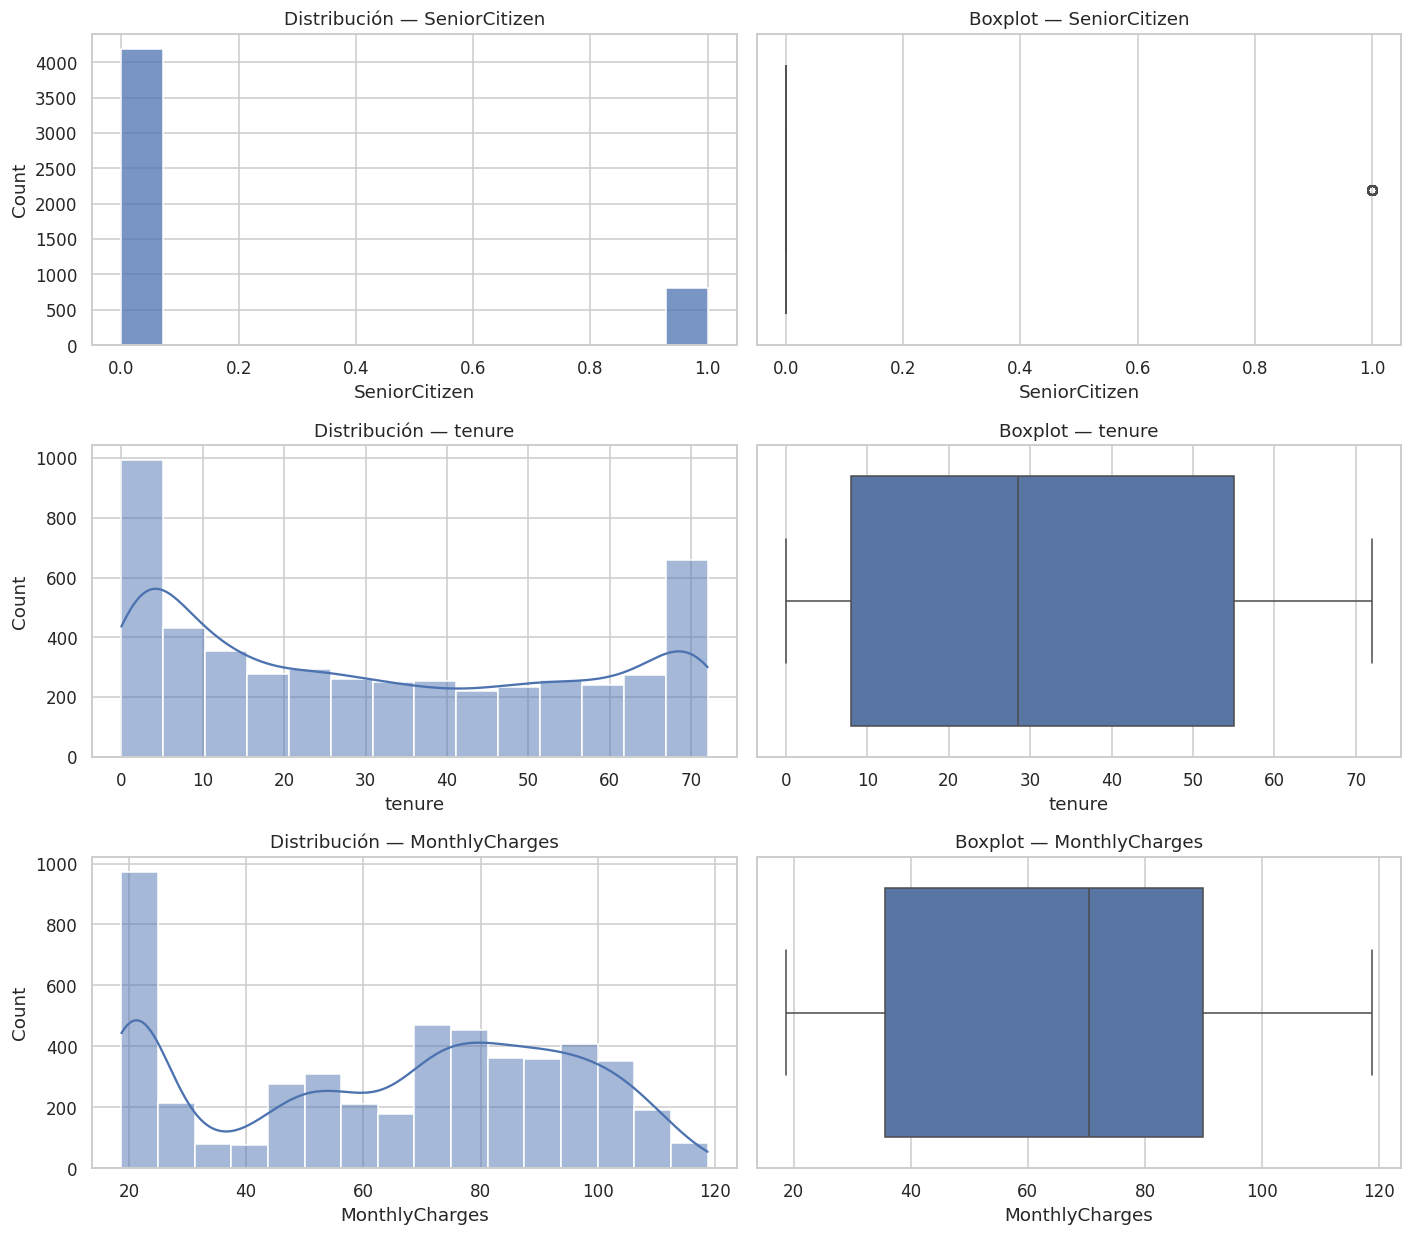

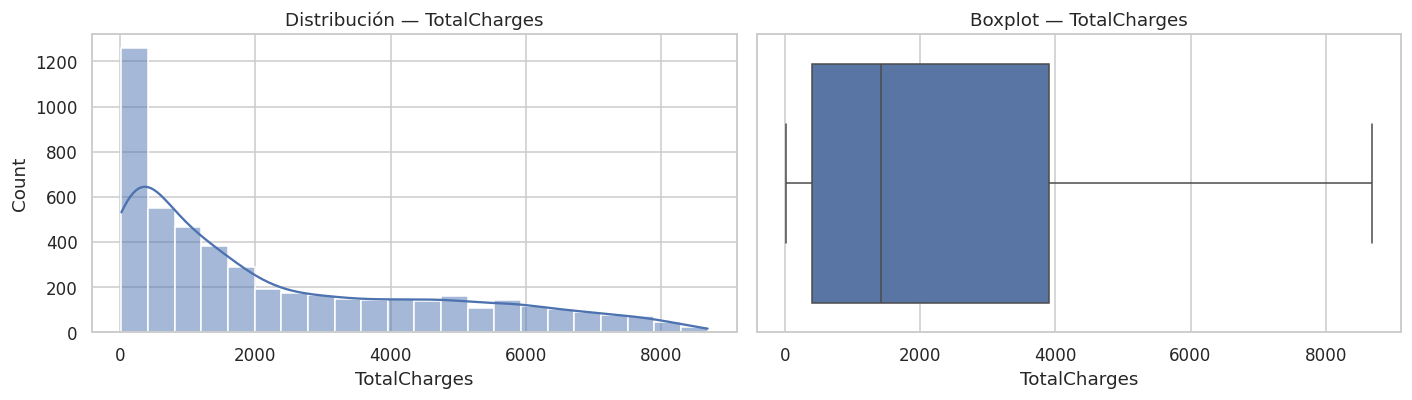

In [78]:
def sample_series(data, column, max_sample=MAX_SAMPLE):
    series = data[column].dropna()
    if len(series) > max_sample:
        series = series.sample(max_sample, random_state=RANDOM_STATE)
    return series


def plot_numeric_distributions(data, columns, batch_size=3):
    for start in range(0, len(columns), batch_size):
        batch = columns[start:start + batch_size]
        fig, axes = plt.subplots(len(batch), 2, figsize=(13, 3.8 * len(batch)))
        if len(batch) == 1:
            axes = np.array([axes])
        for row, col in enumerate(batch):
            values = sample_series(data, col)
            if values.empty:
                axes[row, 0].text(0.5, 0.5, "Sin datos", ha="center", va="center")
                axes[row, 1].axis("off")
                continue
            sns.histplot(values, kde=values.nunique() > 2, color=sns.color_palette()[0], ax=axes[row, 0])
            axes[row, 0].set_title(f"Distribución — {col}")
            axes[row, 0].set_xlabel(col)
            sns.boxplot(x=values, ax=axes[row, 1])
            axes[row, 1].set_title(f"Boxplot — {col}")
            axes[row, 1].set_xlabel(col)
        plt.tight_layout()
        plt.show()


plot_numeric_distributions(analysis_df, numeric_cols)

In [79]:
# Estadísticas adicionales para variables numéricas
if numeric_cols:
    numeric_stats = analysis_df[numeric_cols].agg(
        ["count", "mean", "median", "std", "min", "max", "skew", "kurt"]
    ).T
    numeric_stats["missing_pct"] = 100 * analysis_df[numeric_cols].isna().mean()
    display(numeric_stats.sort_values("skew", key=lambda values: values.abs(), ascending=False))
else:
    print("No se detectaron variables numéricas.")

,count,mean,median,std,min,max,skew,kurt,missing_pct
SeniorCitizen,"7,043.000",0.162,0.000,0.369,0.000,1.000,1.834,1.363,0.000
TotalCharges,"7,032.000","2,283.300","1,397.475","2,266.771",18.800,"8,684.800",0.962,-0.232,0.156
tenure,"7,043.000",32.371,29.000,24.559,0.000,72.000,0.240,-1.387,0.000
MonthlyCharges,"7,043.000",64.762,70.350,30.090,18.250,118.750,-0.221,-1.257,0.000


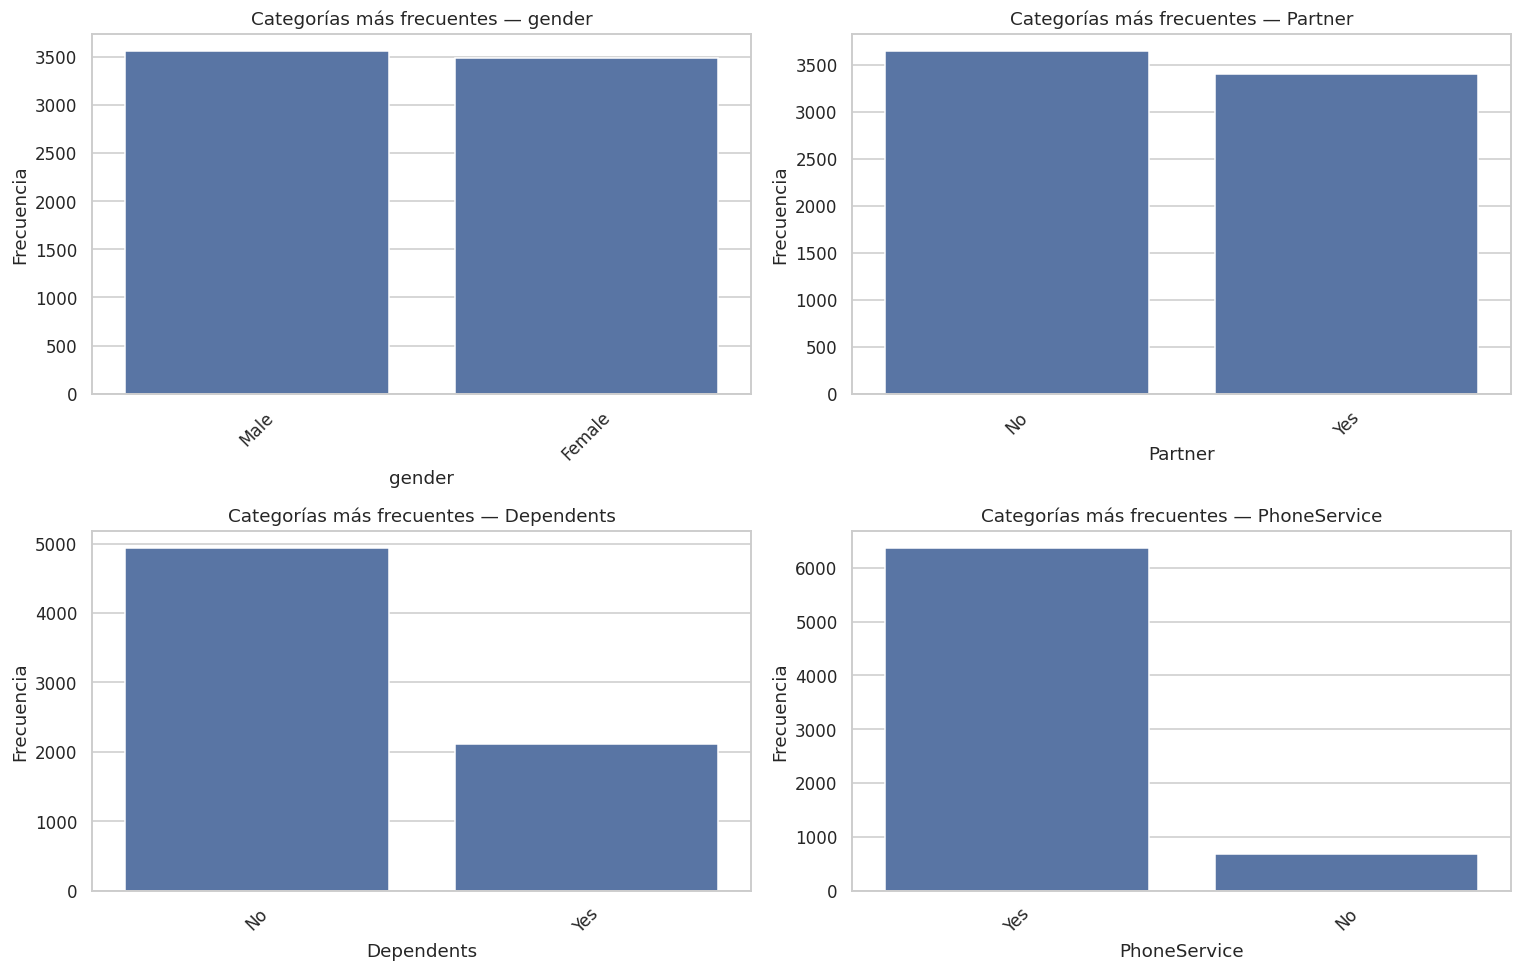

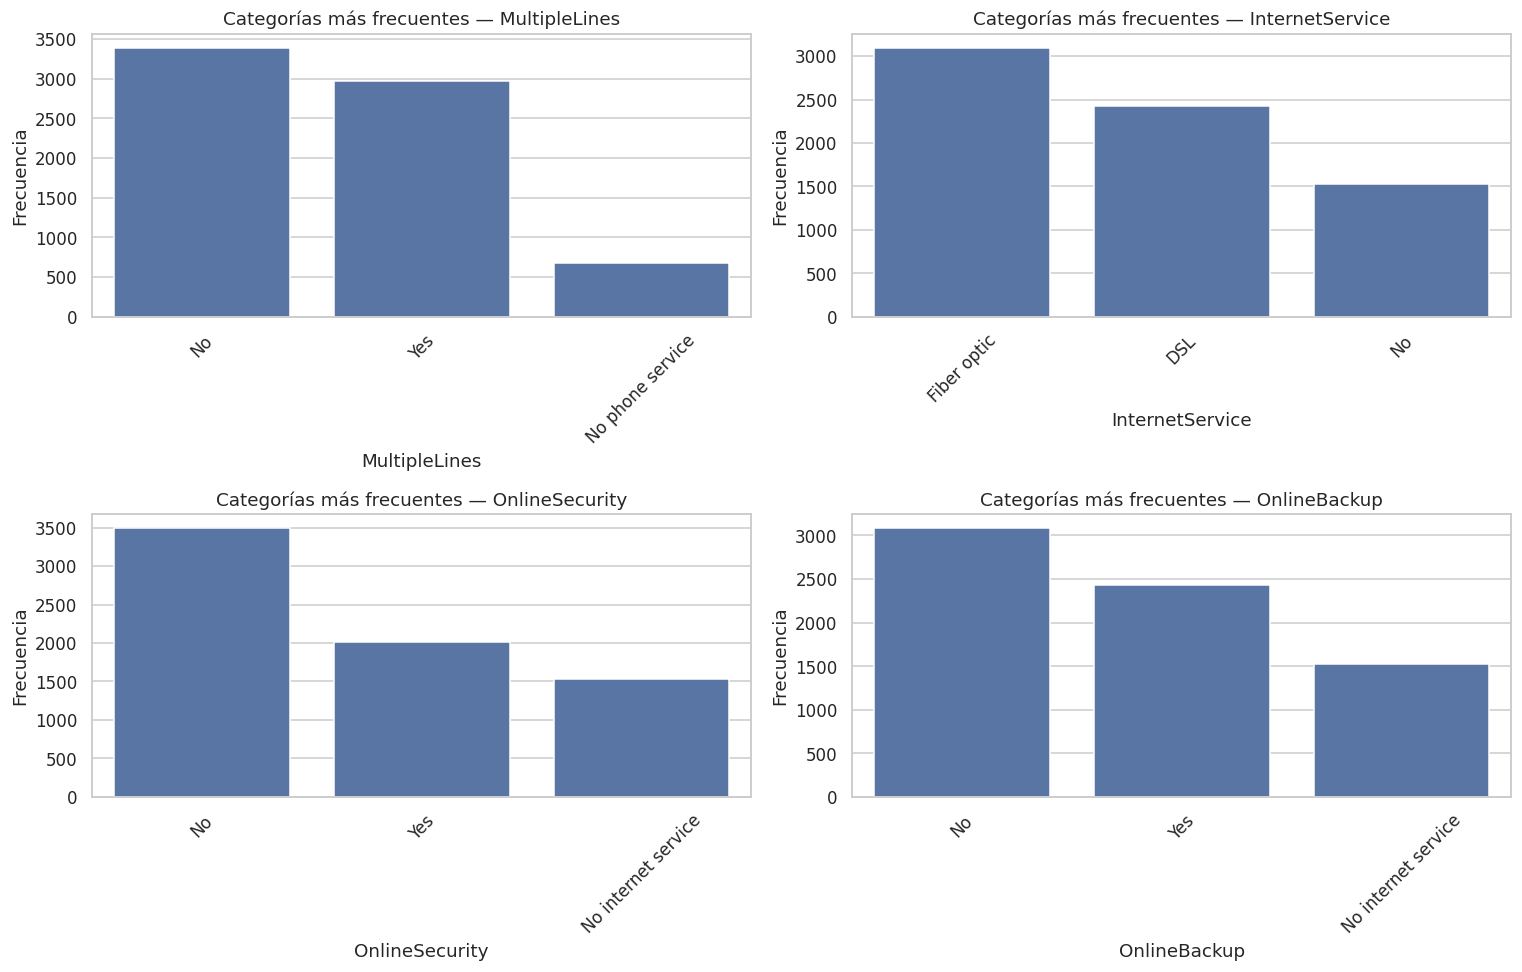

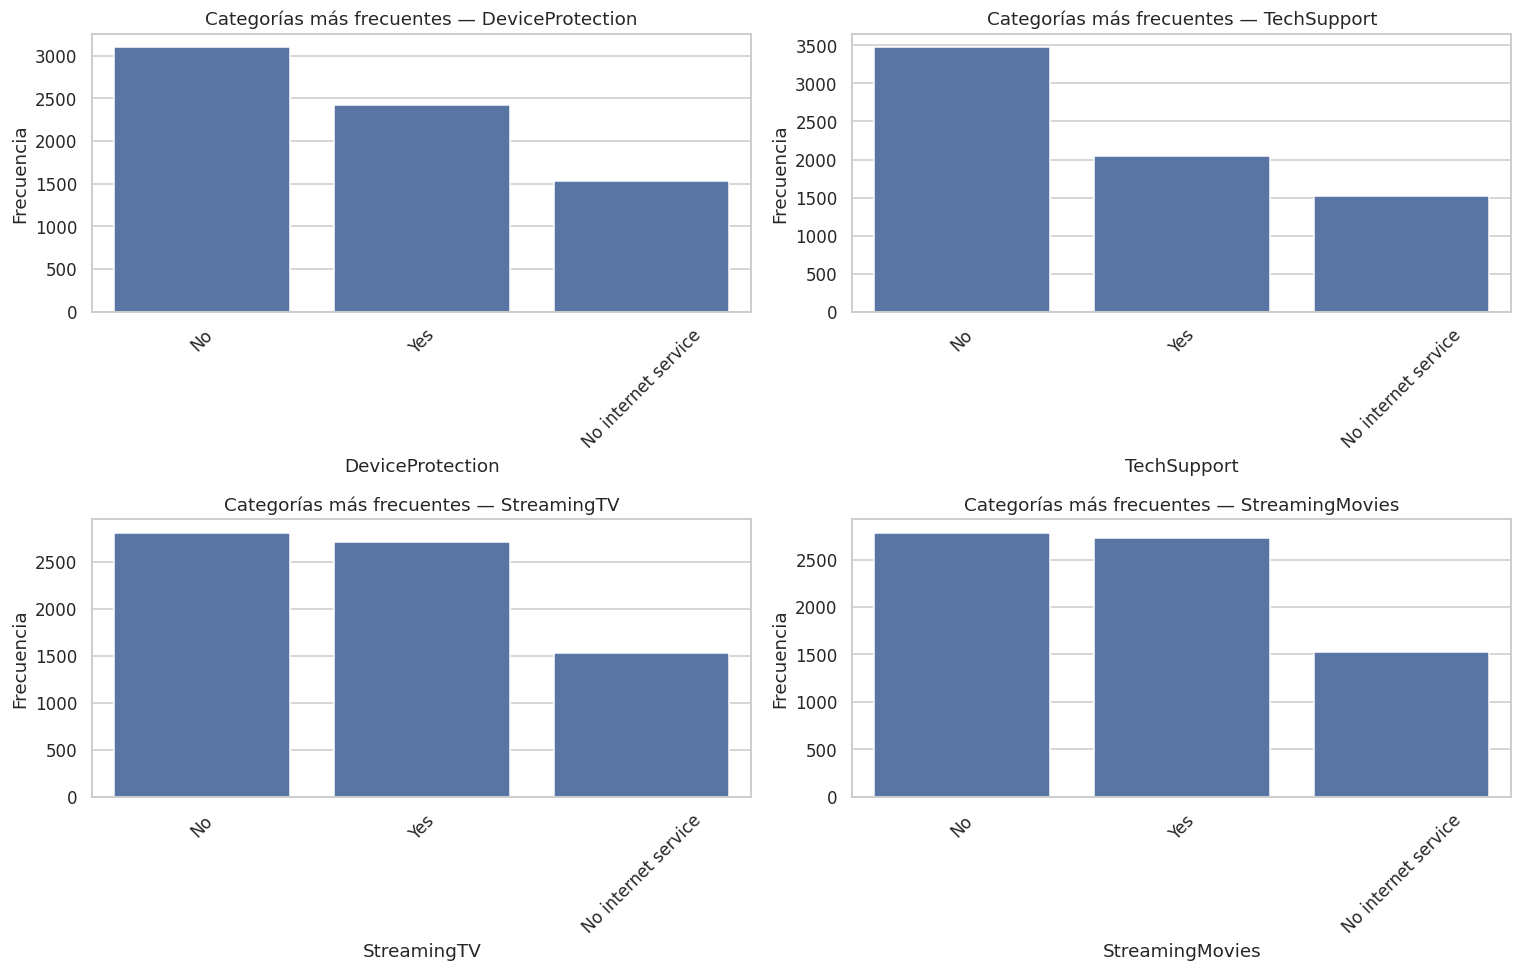

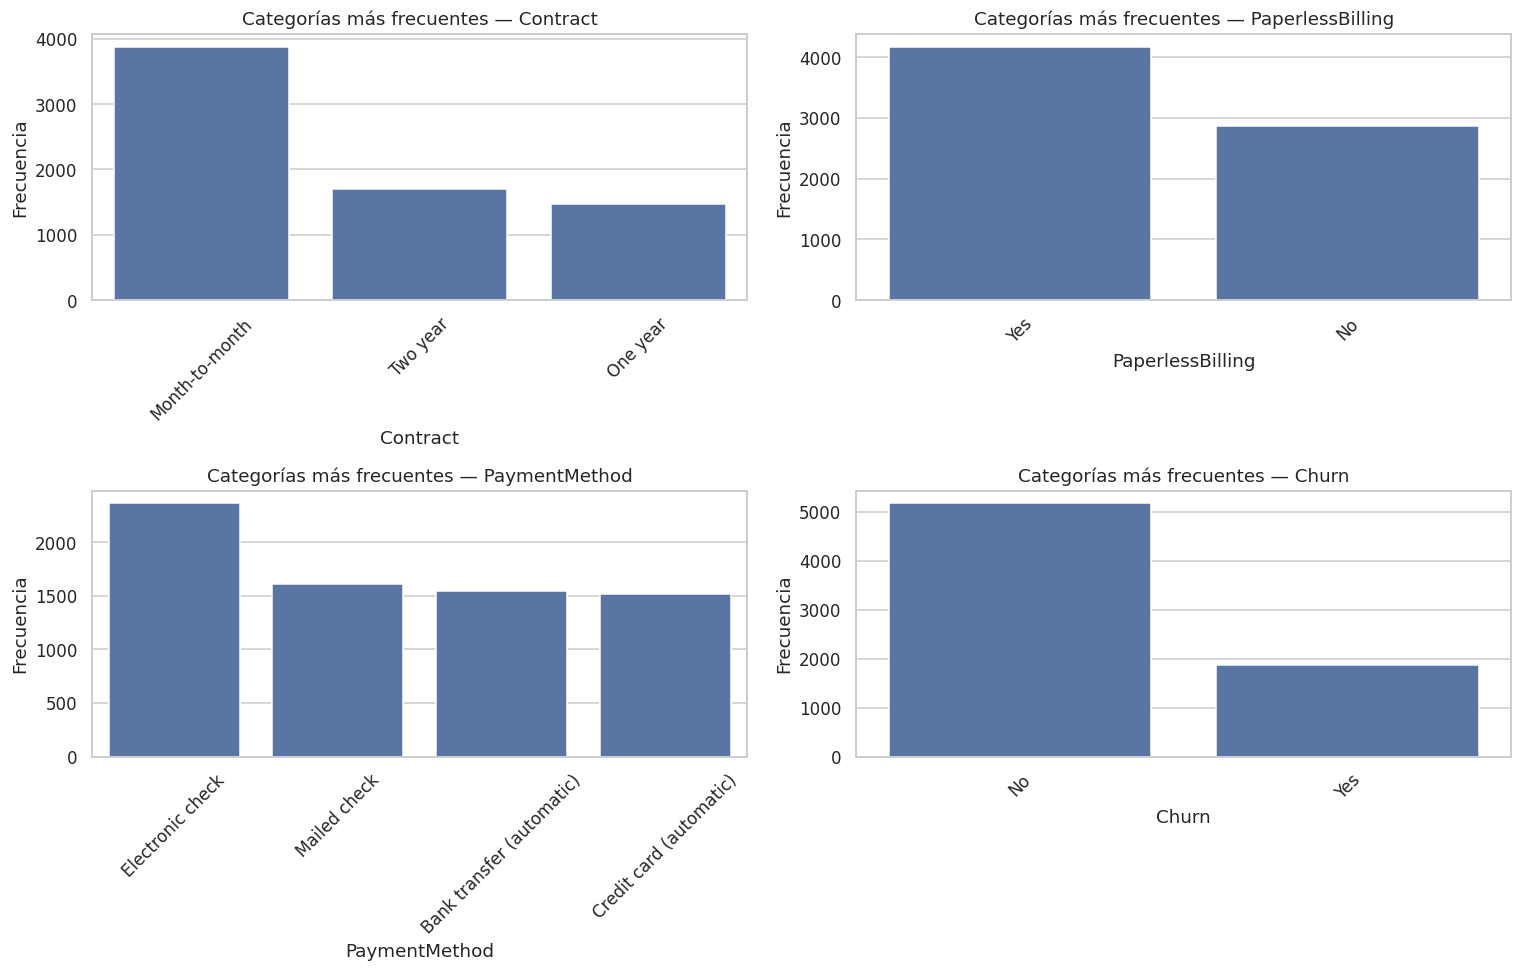

In [80]:
def plot_categorical_distributions(data, columns, batch_size=4):
    for start in range(0, len(columns), batch_size):
        batch = columns[start:start + batch_size]
        ncols = 2
        nrows = int(np.ceil(len(batch) / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.5 * nrows))
        axes = np.array(axes).reshape(-1)
        for ax, col in zip(axes, batch):
            try:
                counts = data[col].astype("string").fillna("<Missing>").value_counts().head(MAX_CATEGORIES)
                sns.barplot(x=counts.index.astype(str), y=counts.values, color=sns.color_palette()[0], ax=ax)
                ax.set_title(f"Categorías más frecuentes — {col}")
                ax.set_xlabel(col)
                ax.set_ylabel("Frecuencia")
                ax.tick_params(axis="x", rotation=45)
            except Exception as error:
                ax.text(0.5, 0.5, f"No se pudo graficar: {error}", ha="center", va="center")
                ax.set_axis_off()
        for ax in axes[len(batch):]:
            ax.set_axis_off()
        plt.tight_layout()
        plt.show()


plot_categorical_distributions(analysis_df, categorical_cols)

In [81]:
# Frecuencias y proporciones de las categorías más frecuentes
for col in categorical_cols:
    print(f"\n{col} — {safe_nunique(analysis_df[col])} categorías únicas")
    freq = analysis_df[col].astype("string").fillna("<Missing>").value_counts(dropna=False)
    summary = pd.DataFrame({
        "count": freq,
        "percentage": 100 * freq / max(len(analysis_df), 1),
    }).head(MAX_CATEGORIES)
    display(summary)


gender — 2 categorías únicas


,count,percentage
gender,,
Male,3555,50.476
Female,3488,49.524



Partner — 2 categorías únicas


,count,percentage
Partner,,
No,3641,51.697
Yes,3402,48.303



Dependents — 2 categorías únicas


,count,percentage
Dependents,,
No,4933,70.041
Yes,2110,29.959


... (22 outputs left out)


PaymentMethod — 4 categorías únicas


,count,percentage
PaymentMethod,,
Electronic check,2365,33.579
Mailed check,1612,22.888
Bank transfer (automatic),1544,21.922
Credit card (automatic),1522,21.610



Churn — 2 categorías únicas


,count,percentage
Churn,,
No,5174,73.463
Yes,1869,26.537


In [82]:
def choose_time_frequency(series):
    valid = series.dropna()
    if valid.empty:
        return "M"
    span_days = (valid.max() - valid.min()).total_seconds() / 86400
    if span_days <= 90:
        return "D"
    if span_days <= 730:
        return "W"
    if span_days <= 3650:
        return "M"
    return "Q"


for col in datetime_cols:
    dates = analysis_df[col].dropna()
    if dates.empty:
        print(f"{col}: no contiene fechas válidas.")
        continue
    print(f"{col}: desde {dates.min()} hasta {dates.max()} ({dates.nunique():,} fechas únicas)")
    freq = choose_time_frequency(dates)
    counts = dates.dt.to_period(freq).value_counts().sort_index()
    plt.figure(figsize=(12, 4))
    plt.plot(counts.index.astype(str), counts.values, marker="o", linewidth=1)
    plt.title(f"Cantidad de observaciones a lo largo del tiempo — {col}")
    plt.xlabel("Período")
    plt.ylabel("Cantidad de registros")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 7. Análisis bivariado — relaciones entre variables

Se exploran relaciones entre pares de variables según sus tipos. Como el número de combinaciones puede crecer rápidamente, los gráficos están limitados por `MAX_PAIR_PLOTS` y `MAX_BIVARIATE_PLOTS`. Las tablas de correlación muestran asociaciones, no causalidad.

Correlación de Pearson


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000,0.017,0.220,0.102
tenure,0.017,1.000,0.248,0.826
MonthlyCharges,0.220,0.248,1.000,0.651
TotalCharges,0.102,0.826,0.651,1.000


Correlación de Spearman


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000,0.019,0.221,0.107
tenure,0.019,1.000,0.276,0.889
MonthlyCharges,0.221,0.276,1.000,0.638
TotalCharges,0.107,0.889,0.638,1.000


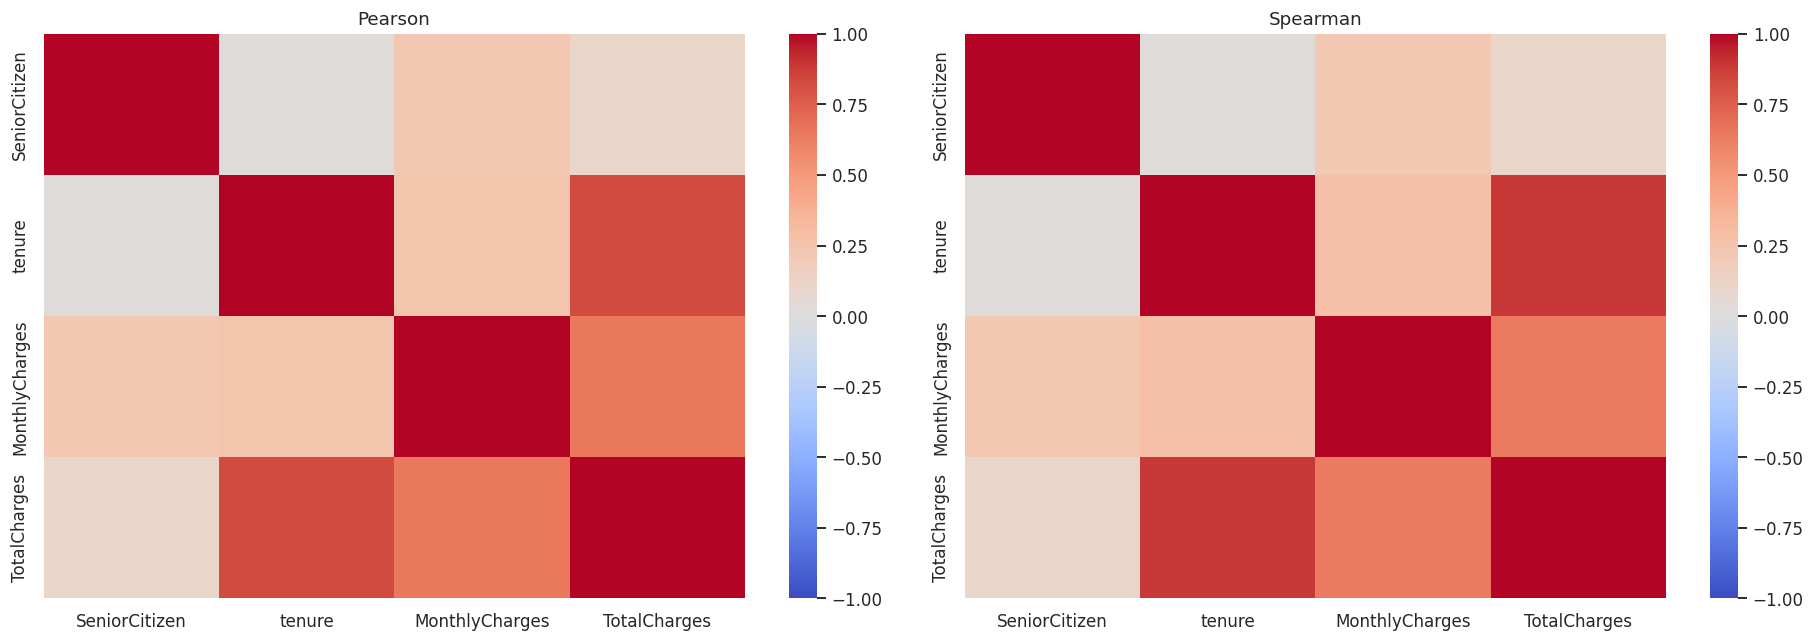

In [83]:
# Correlaciones de Pearson y Spearman
if len(numeric_cols) >= 2:
    selected_numeric = numeric_cols[:MAX_CORR_FEATURES]
    pearson_corr = analysis_df[selected_numeric].corr(method="pearson")
    spearman_corr = analysis_df[selected_numeric].corr(method="spearman")

    print("Correlación de Pearson")
    display(pearson_corr)
    print("Correlación de Spearman")
    display(spearman_corr)

    fig, axes = plt.subplots(1, 2, figsize=(17, max(6, len(selected_numeric) * 0.35)))
    sns.heatmap(pearson_corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0])
    axes[0].set_title("Pearson")
    sns.heatmap(spearman_corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[1])
    axes[1].set_title("Spearman")
    plt.tight_layout()
    plt.show()
    if len(numeric_cols) > MAX_CORR_FEATURES:
        print(f"Se muestran las primeras {MAX_CORR_FEATURES} de {len(numeric_cols)} variables numéricas.")
else:
    print("Se necesitan al menos dos variables numéricas para calcular correlaciones.")

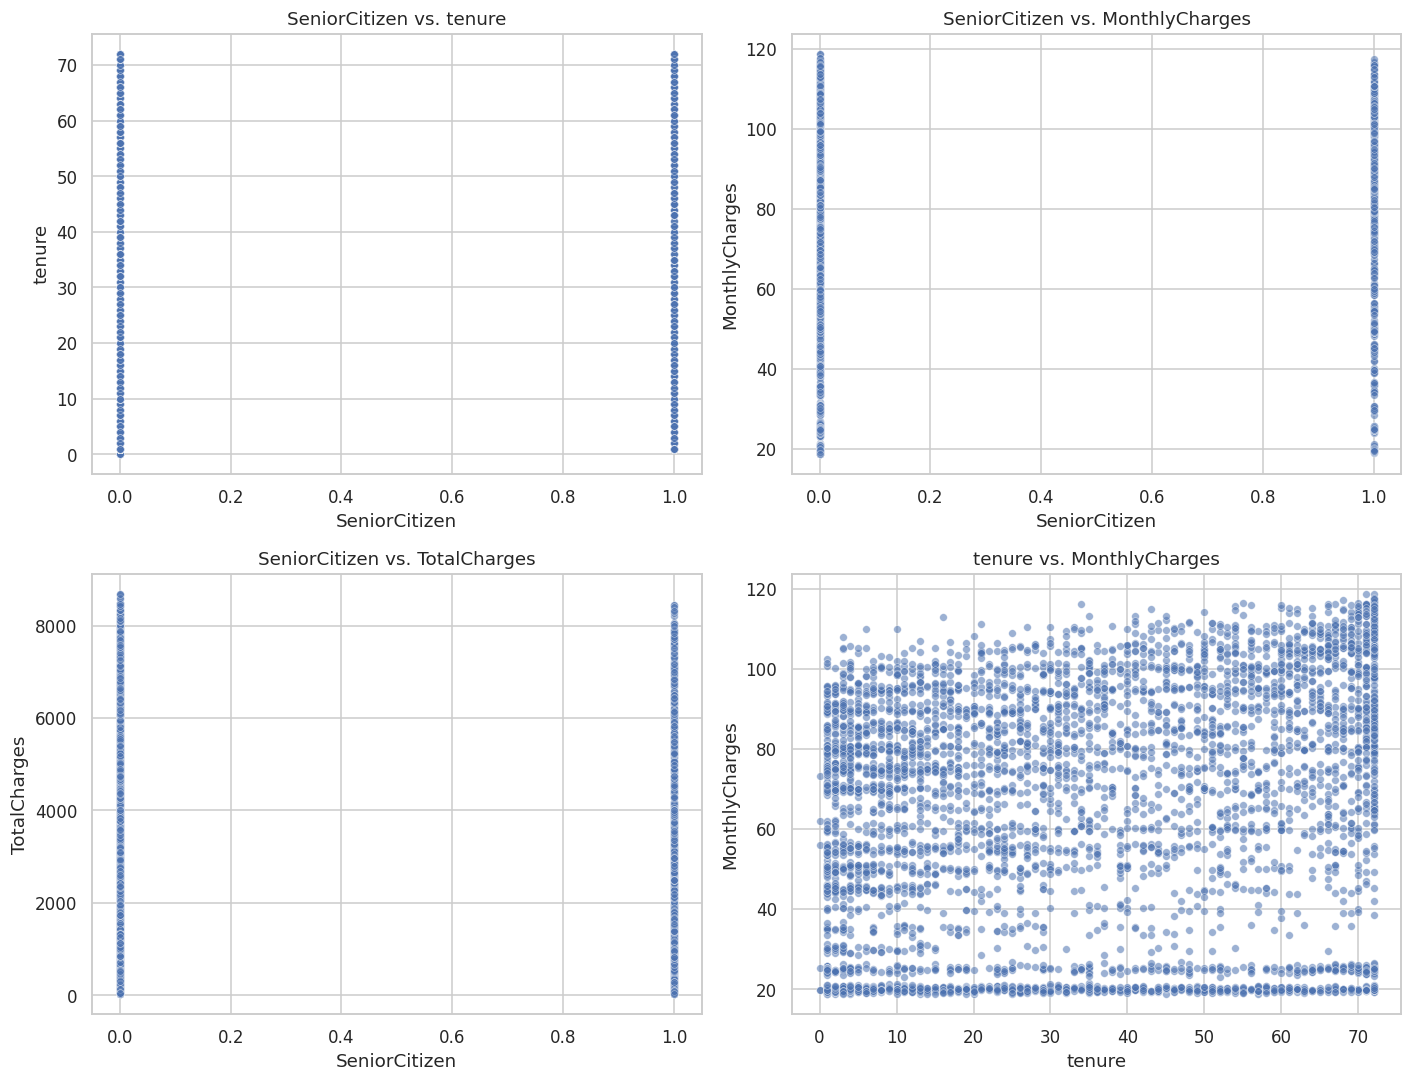

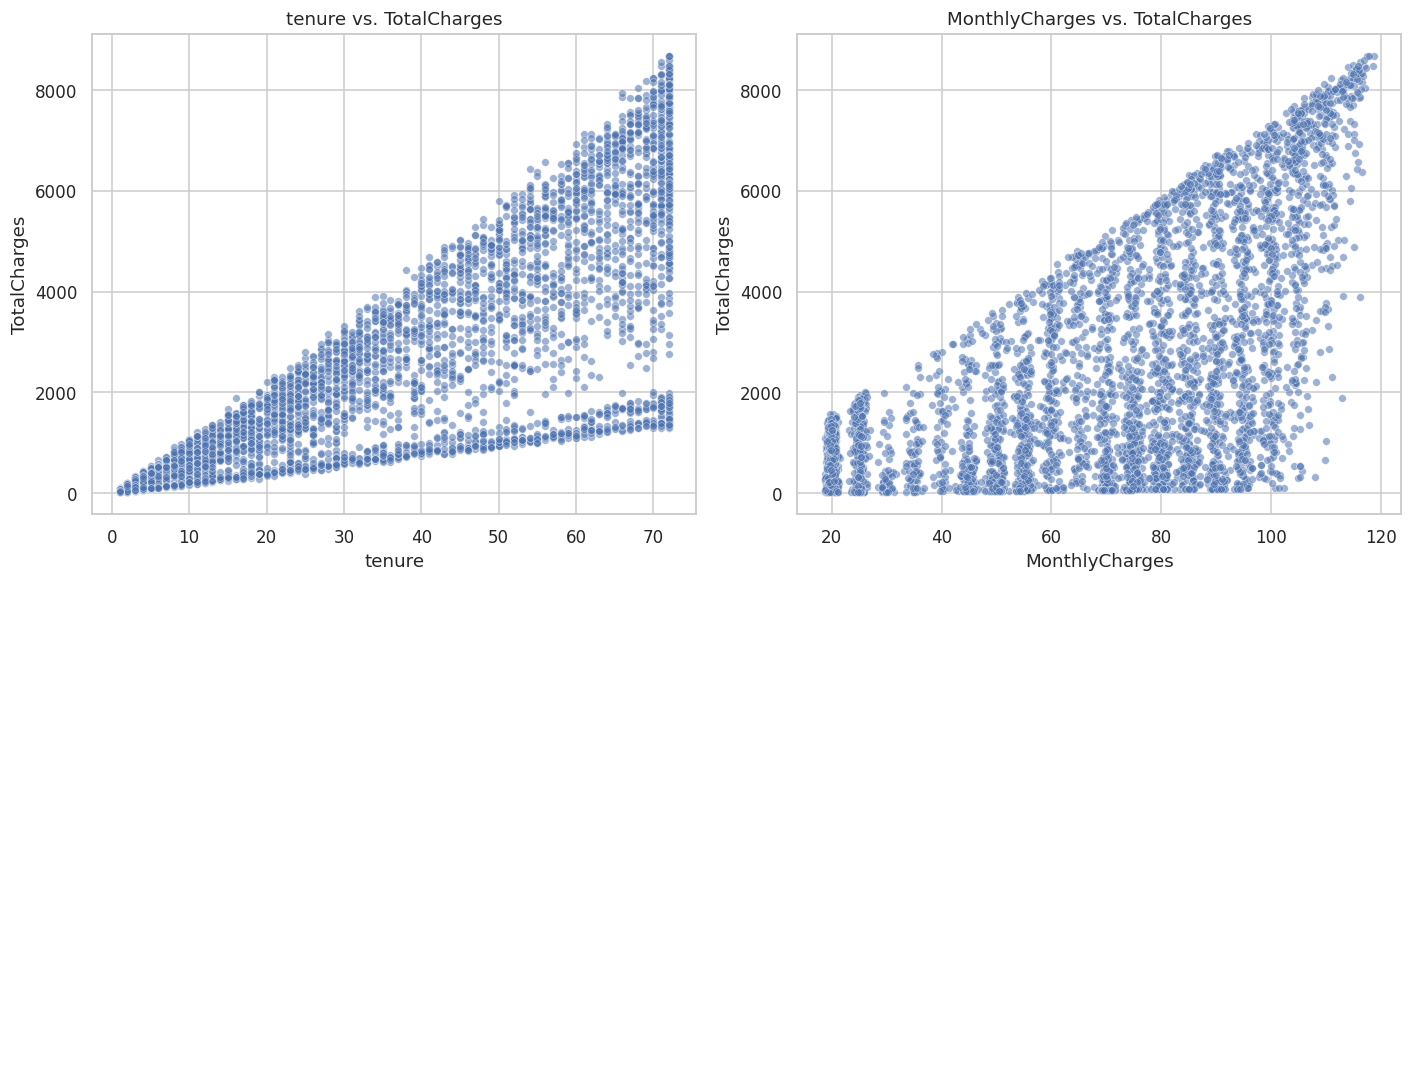

In [84]:
# Pares numéricos: scatterplots (muestra limitada y máximo de gráficos configurable)
numeric_pairs = list(combinations(numeric_cols, 2))[:MAX_PAIR_PLOTS]
if numeric_pairs:
    plot_data = analysis_df[numeric_cols].sample(
        n=min(MAX_SAMPLE, len(analysis_df)), random_state=RANDOM_STATE
    )
    for start in range(0, len(numeric_pairs), 4):
        batch = numeric_pairs[start:start + 4]
        fig, axes = plt.subplots(2, 2, figsize=(13, 10))
        for ax, (x_col, y_col) in zip(axes.flat, batch):
            sns.scatterplot(data=plot_data, x=x_col, y=y_col, alpha=0.55, s=25, ax=ax)
            ax.set_title(f"{x_col} vs. {y_col}")
        for ax in axes.flat[len(batch):]:
            ax.set_axis_off()
        plt.tight_layout()
        plt.show()
else:
    print("No hay pares de variables numéricas para graficar.")

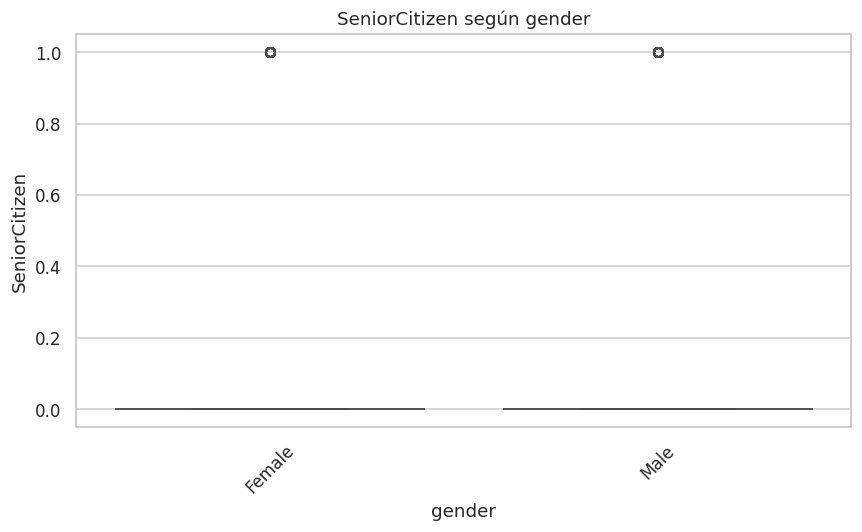

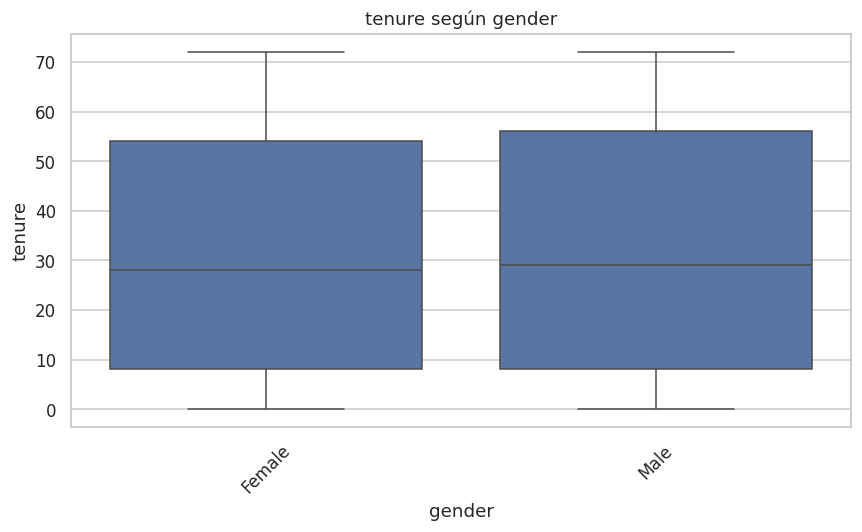

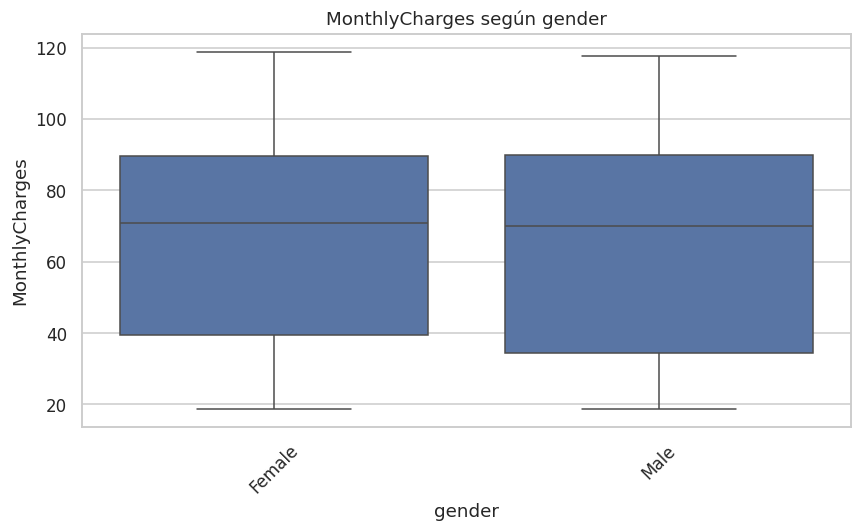

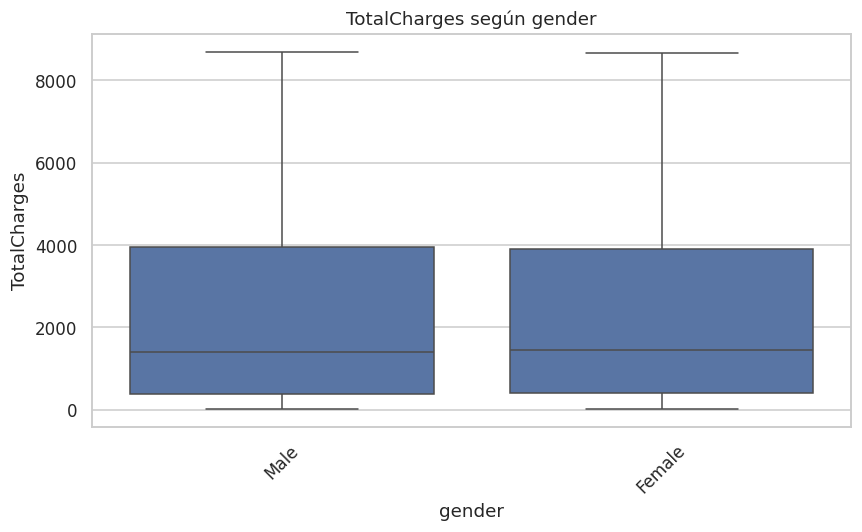

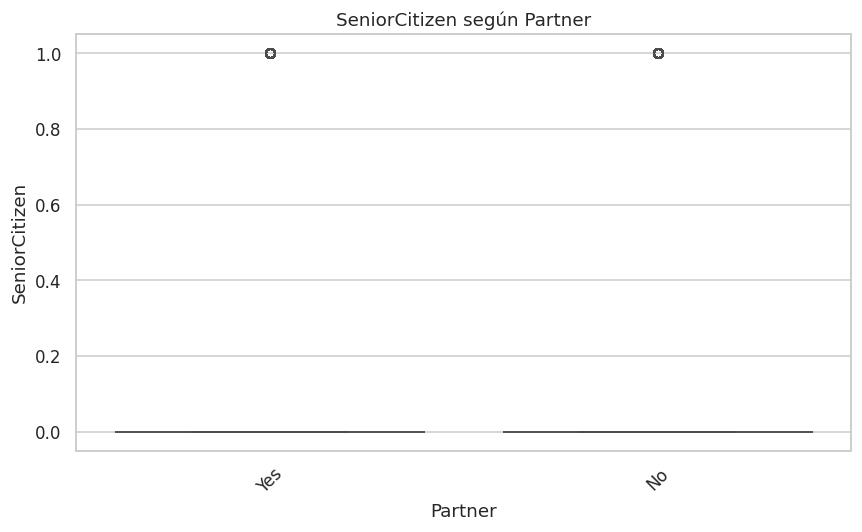

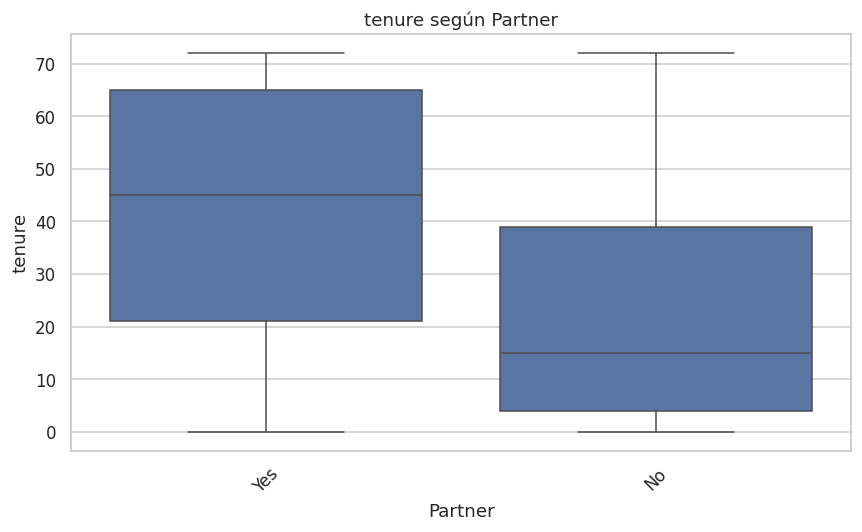

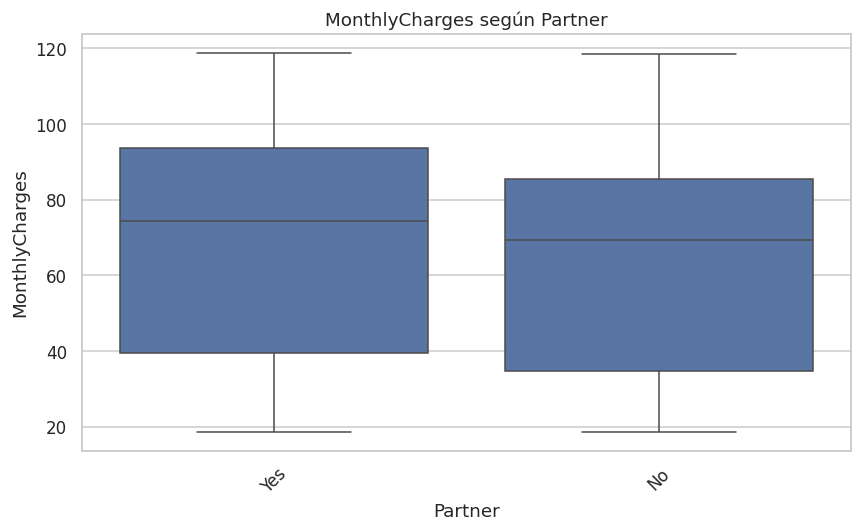

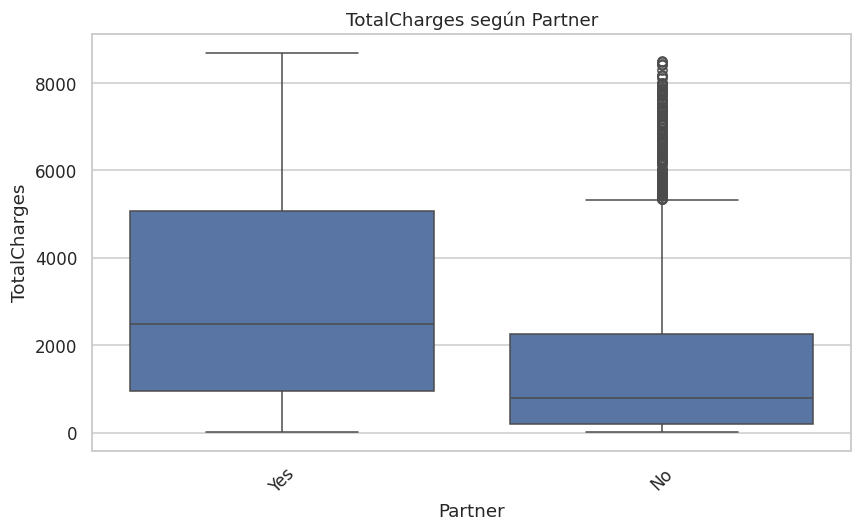

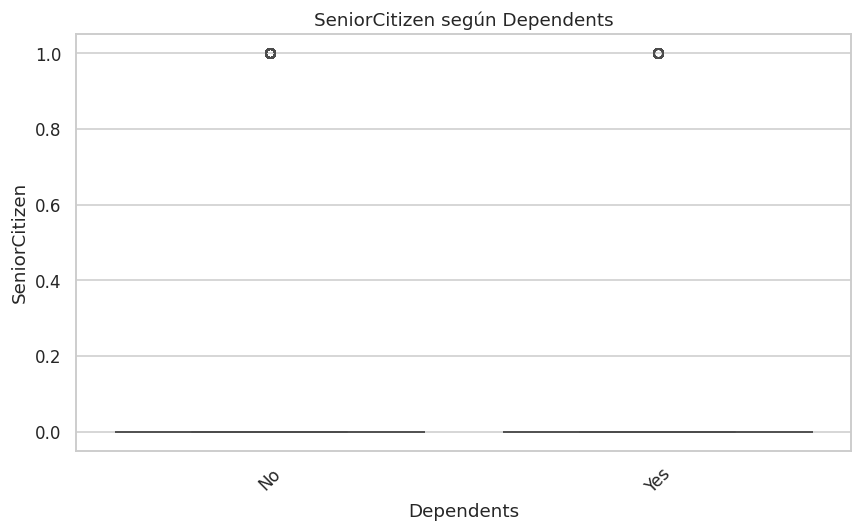

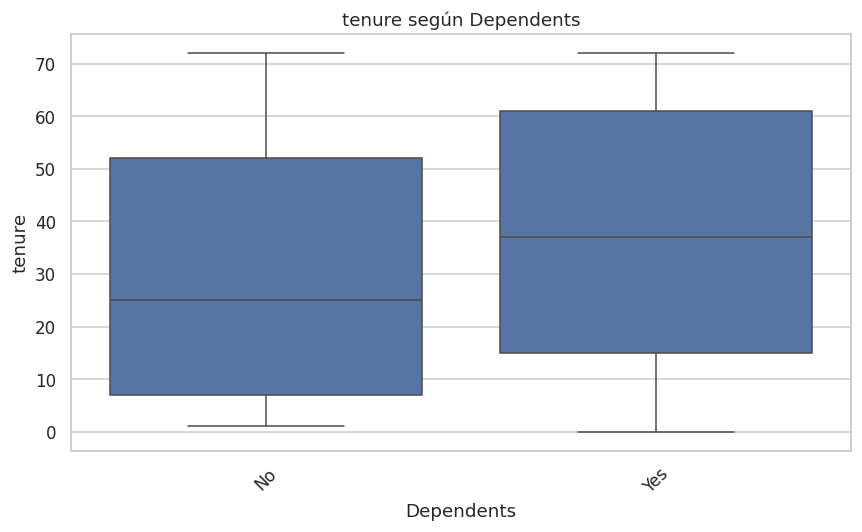

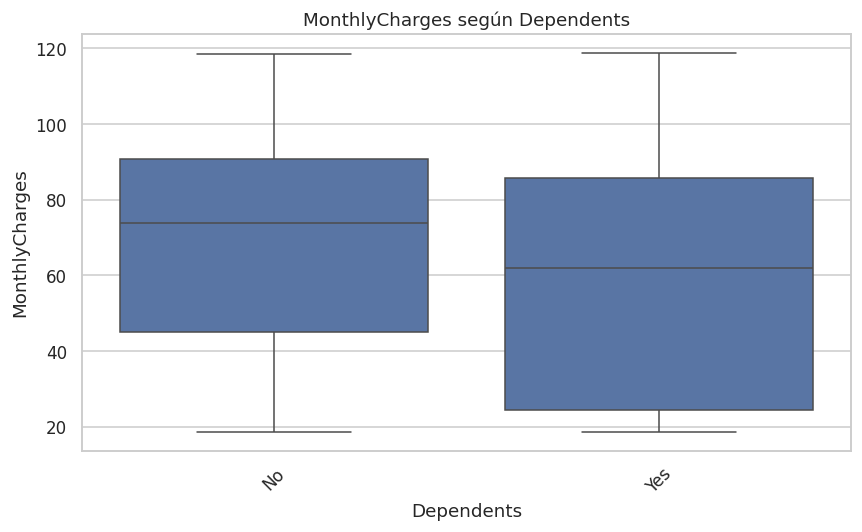

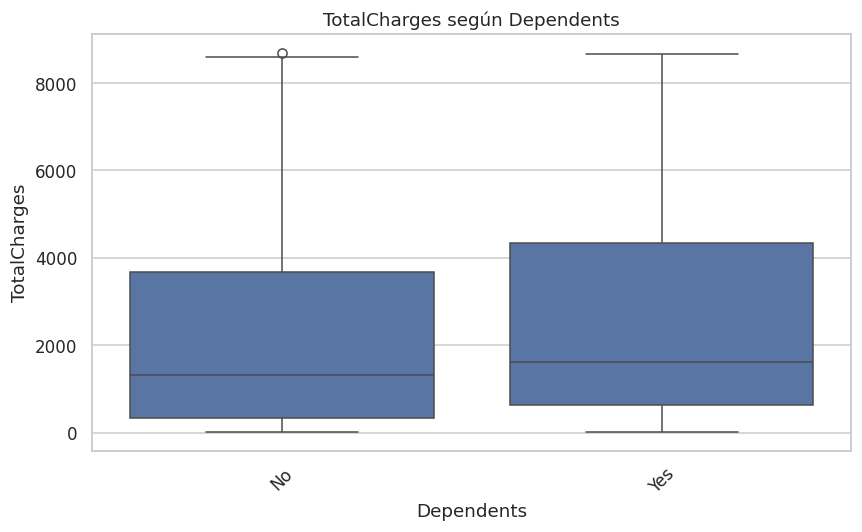

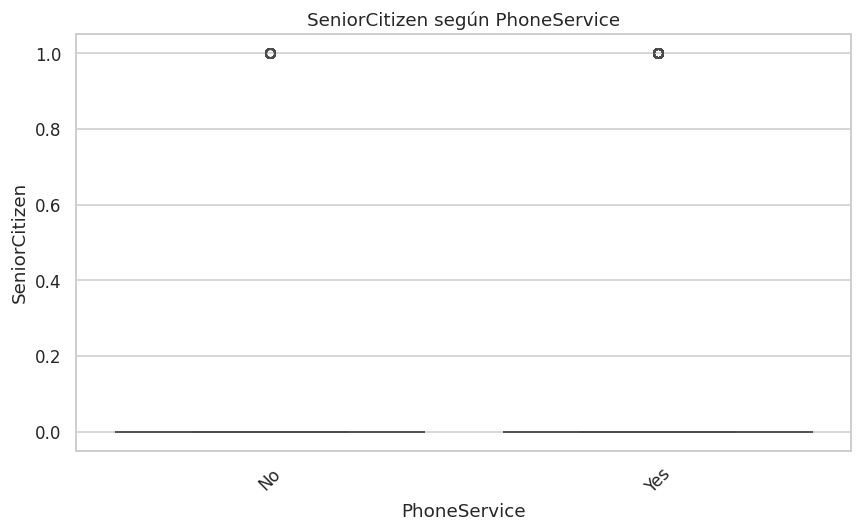

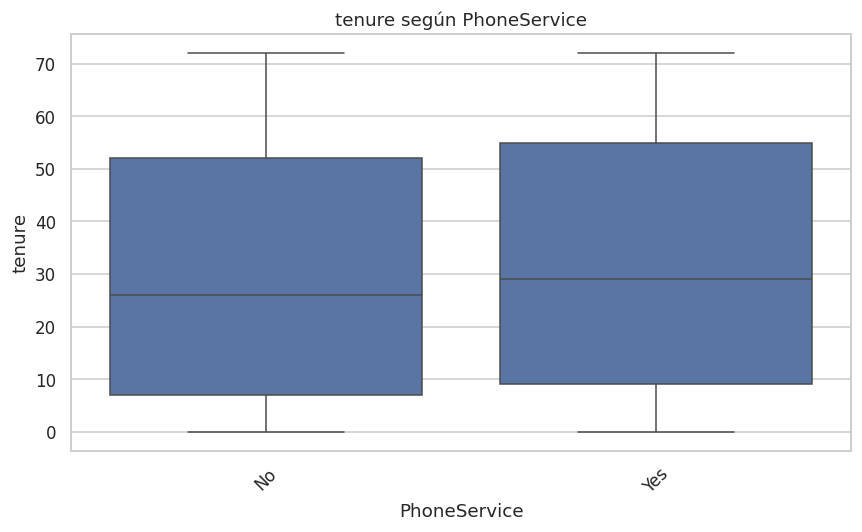

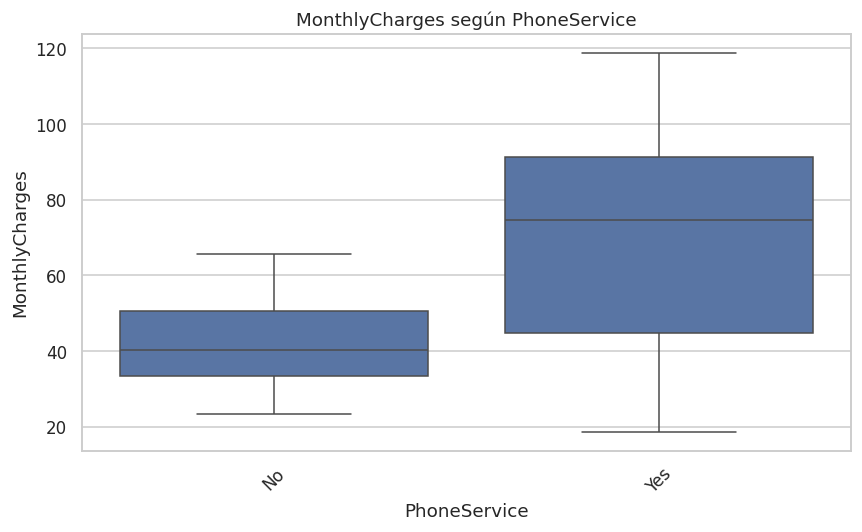

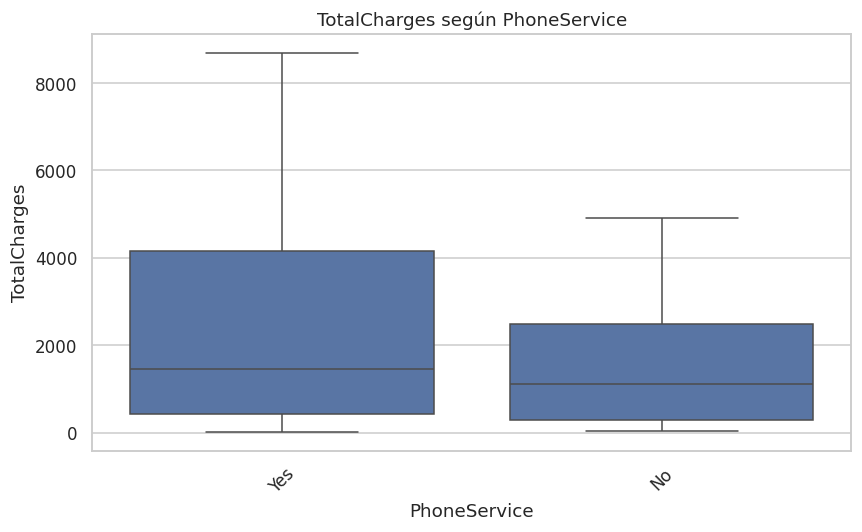

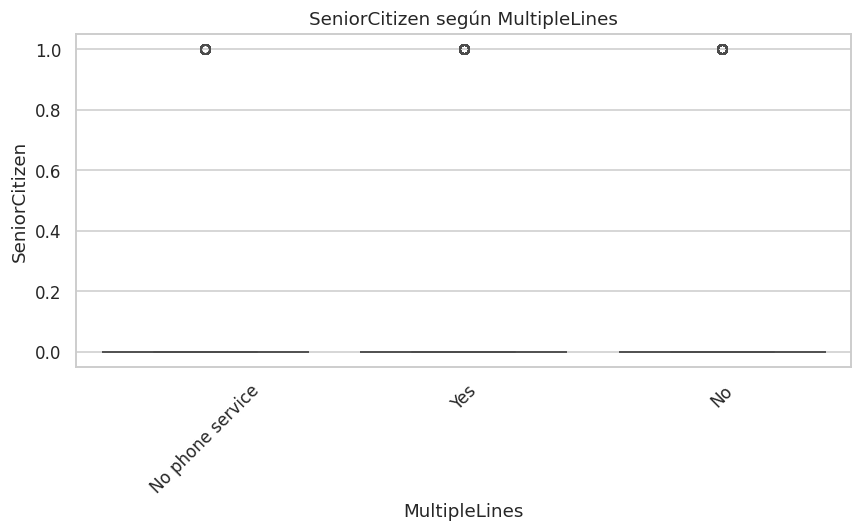

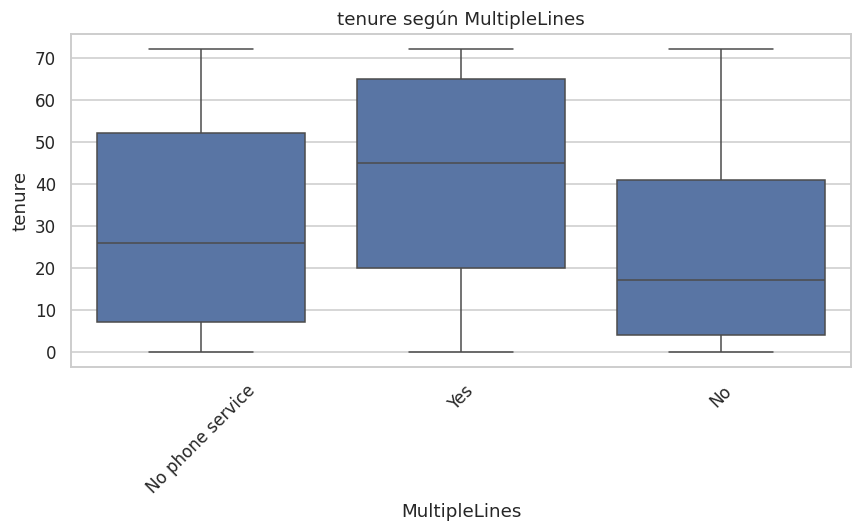

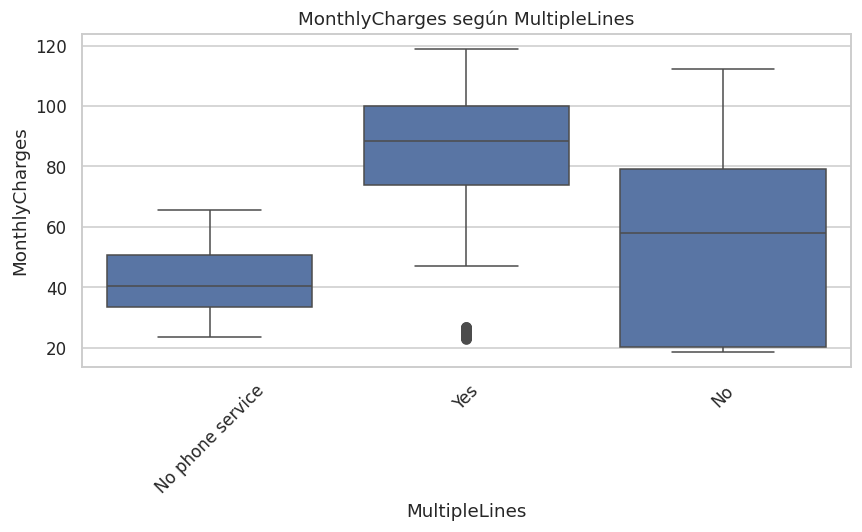

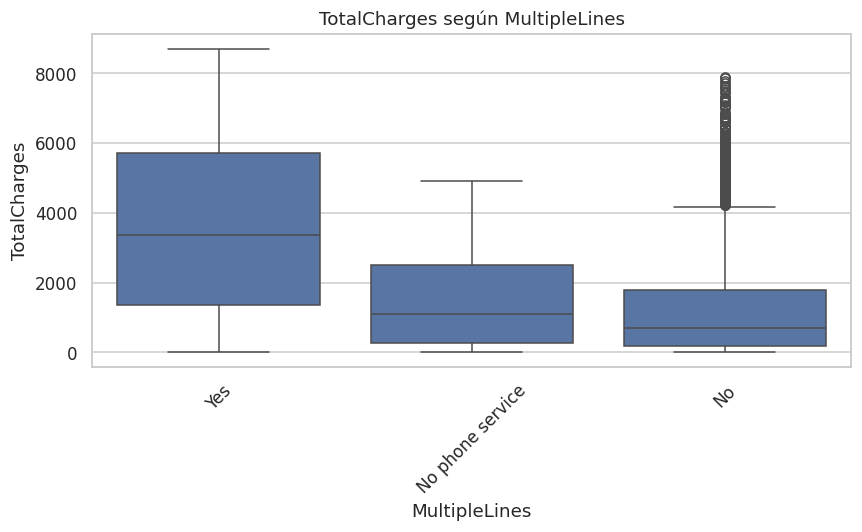

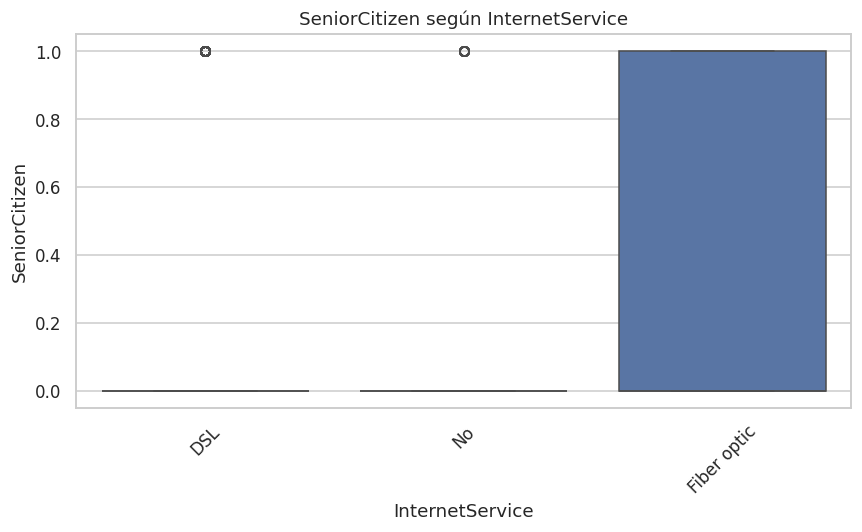

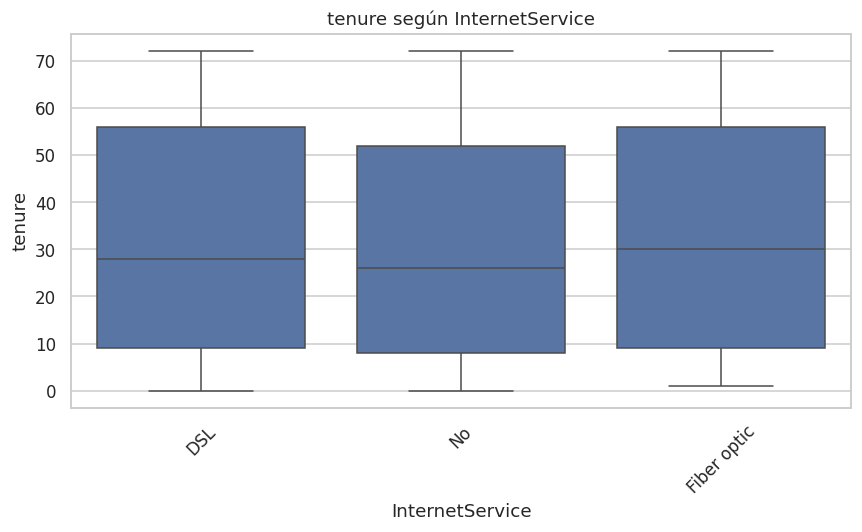

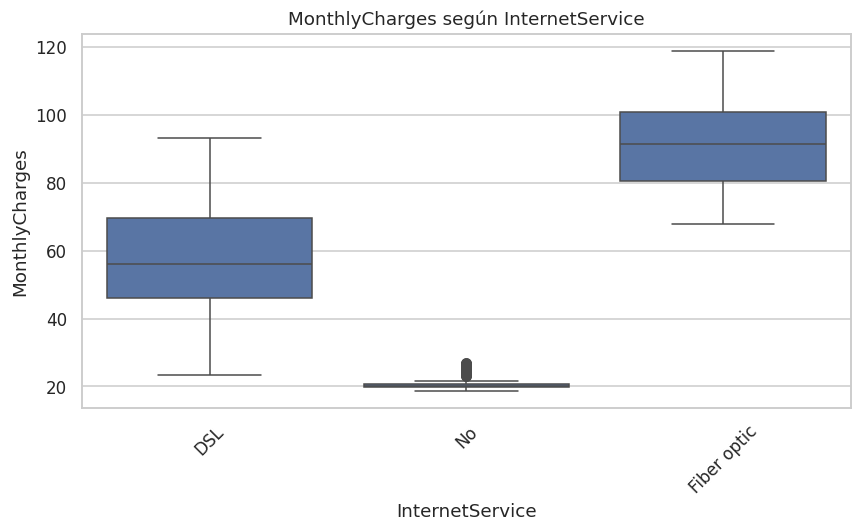

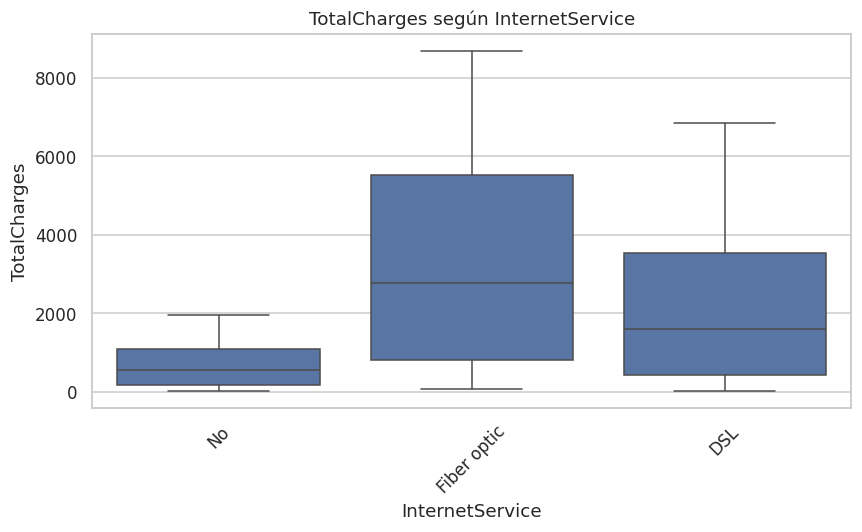

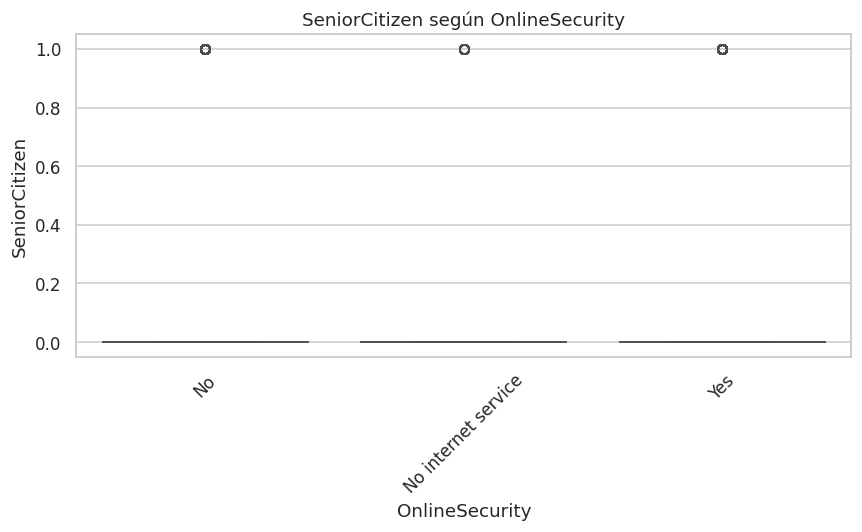

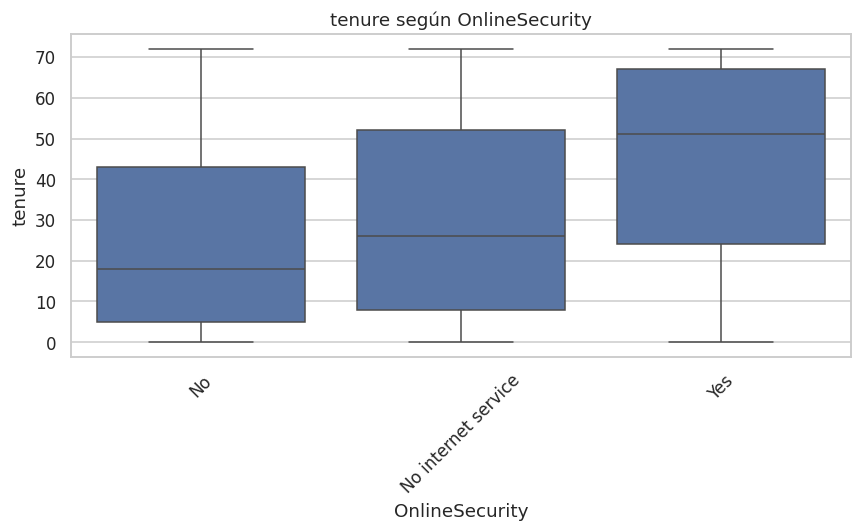

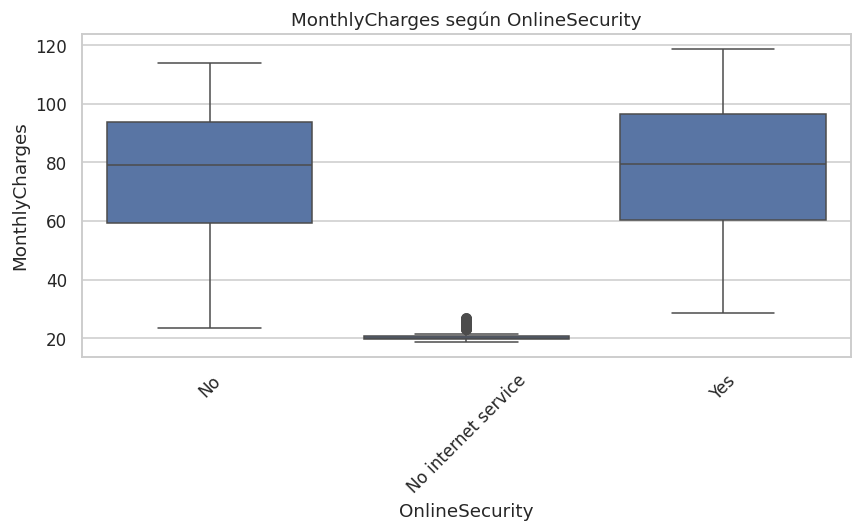

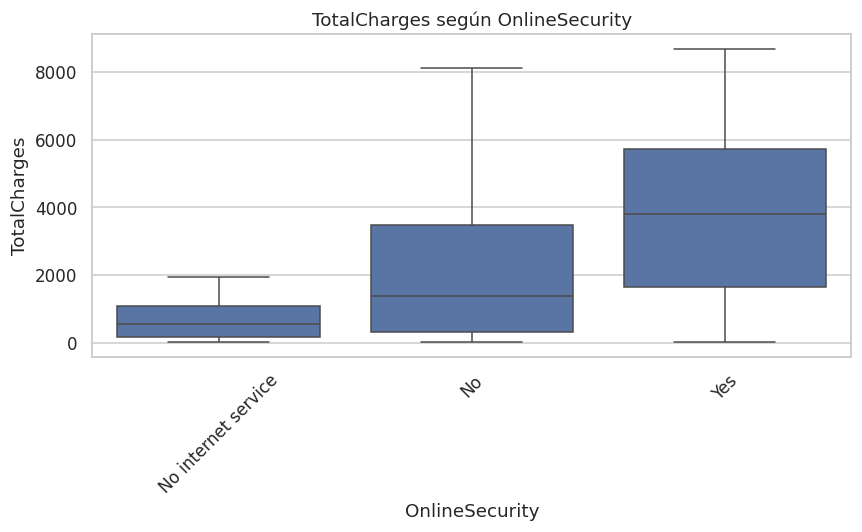

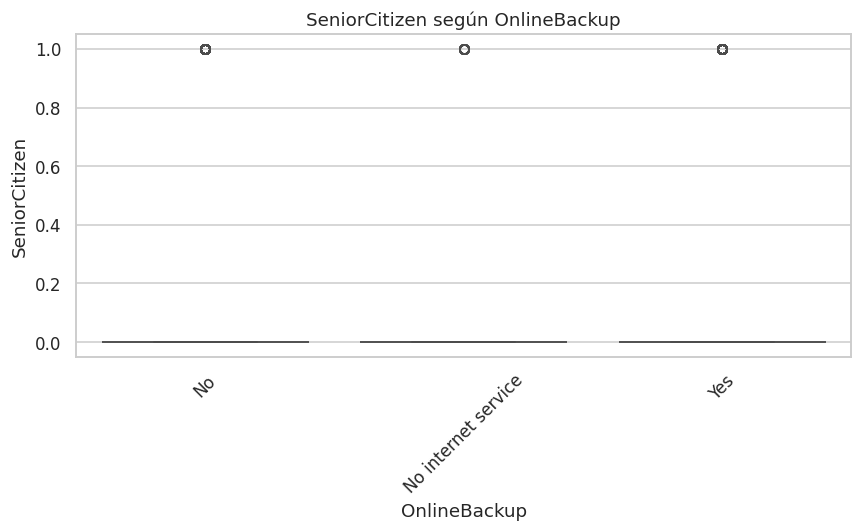

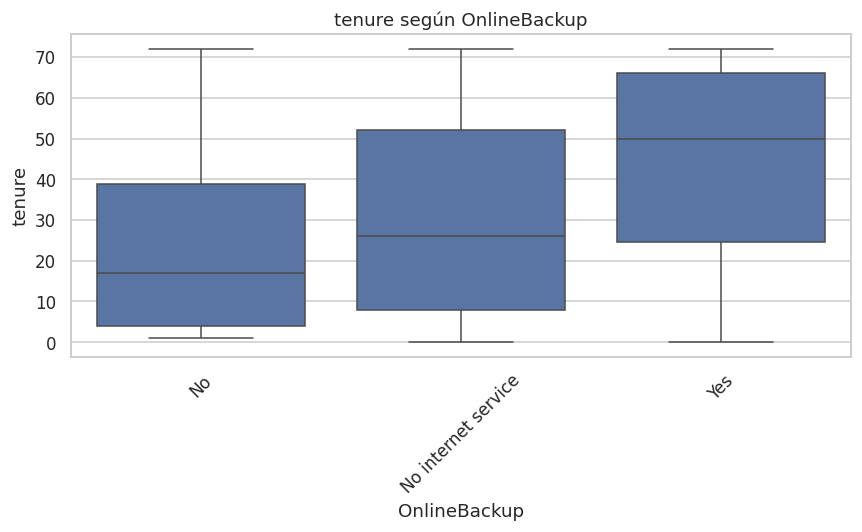

Se graficaron 30 de 64 combinaciones posibles (límite: 30).


In [85]:
# Categórica vs. numérica: boxplots
cat_num_pairs = [(cat, num) for cat in categorical_cols for num in numeric_cols]
plotted = 0
for cat_col, num_col in cat_num_pairs:
    if plotted >= MAX_BIVARIATE_PLOTS:
        break
    top_categories = analysis_df[cat_col].astype("string").value_counts().head(MAX_CATEGORIES).index
    subset = analysis_df.loc[
        analysis_df[cat_col].astype("string").isin(top_categories), [cat_col, num_col]
    ].dropna()
    if subset.empty or subset[cat_col].nunique() < 2:
        continue
    if len(subset) > MAX_SAMPLE:
        subset = subset.sample(MAX_SAMPLE, random_state=RANDOM_STATE)
    plt.figure(figsize=(max(8, min(14, subset[cat_col].nunique() * 0.65)), 5))
    sns.boxplot(data=subset, x=cat_col, y=num_col)
    plt.title(f"{num_col} según {cat_col}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    plotted += 1

if not plotted:
    print("No se encontraron pares categórica-numérica adecuados para graficar.")
elif len(cat_num_pairs) > plotted:
    print(f"Se graficaron {plotted} de {len(cat_num_pairs)} combinaciones posibles (límite: {MAX_BIVARIATE_PLOTS}).")

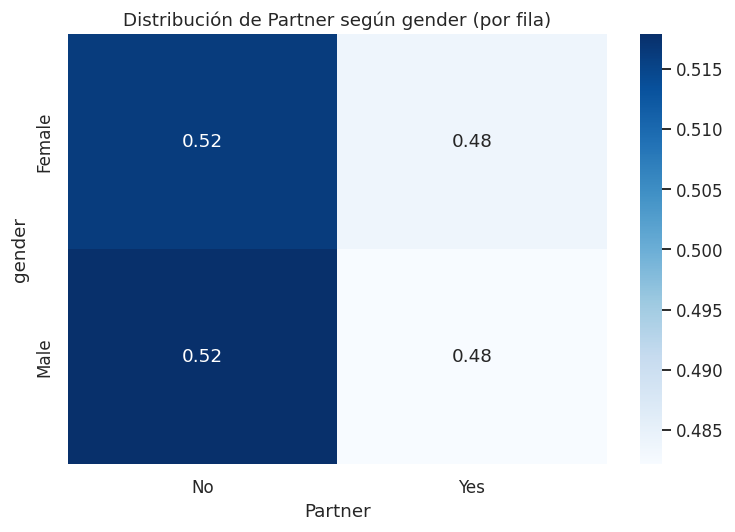

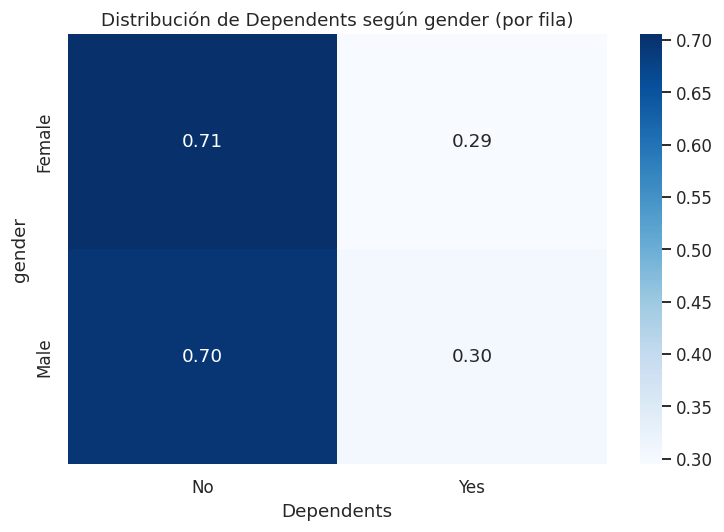

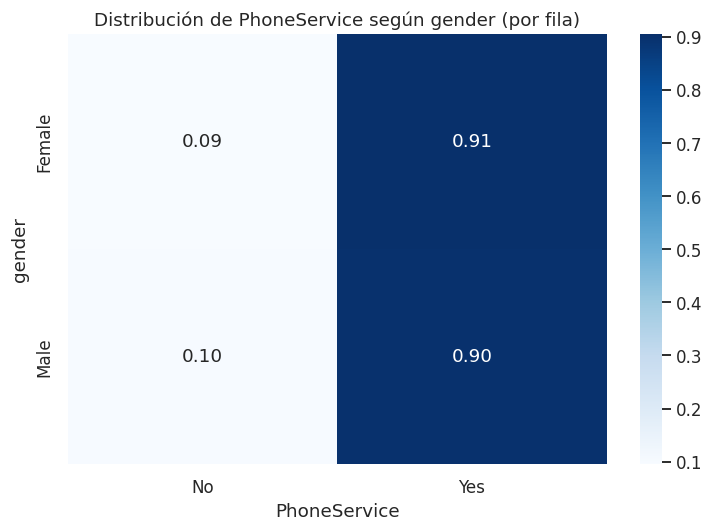

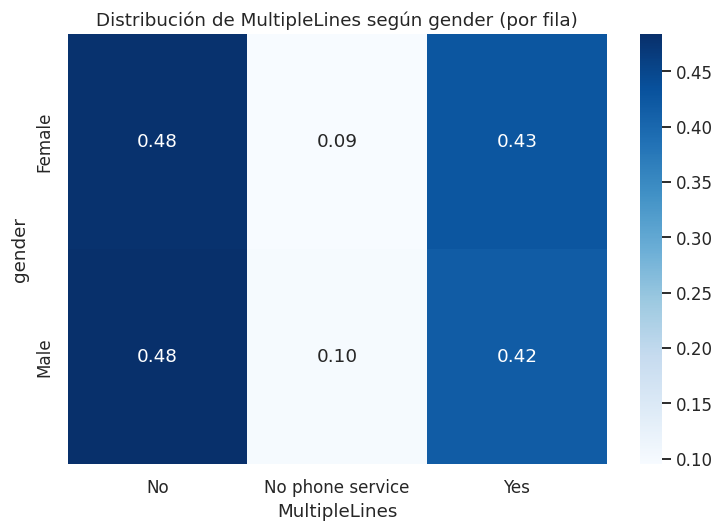

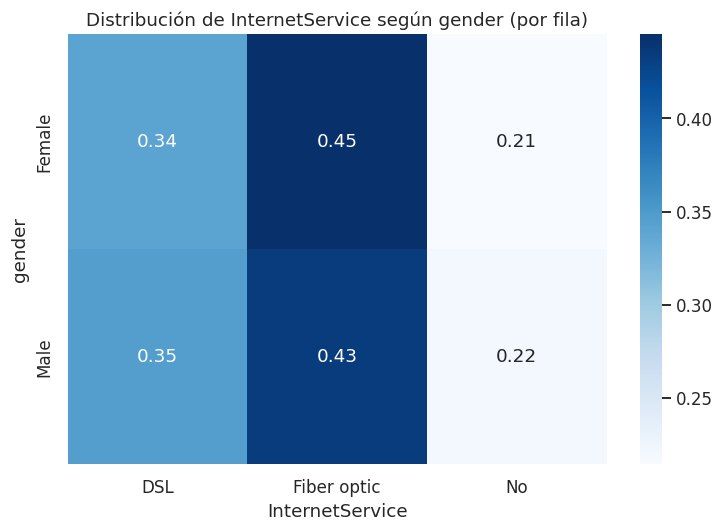

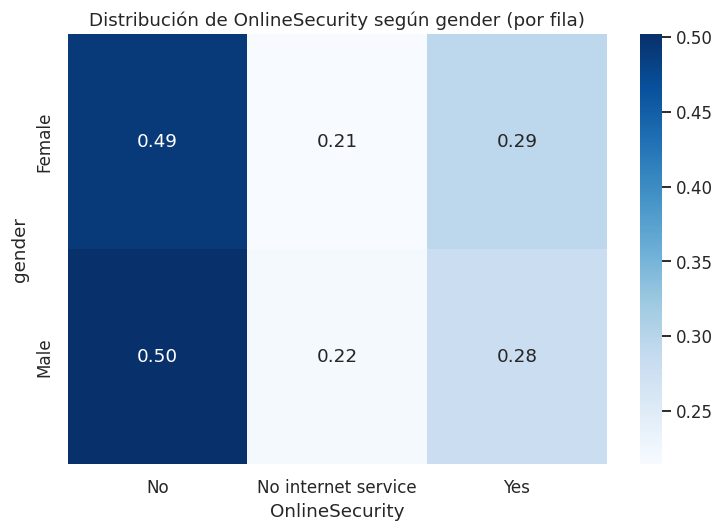

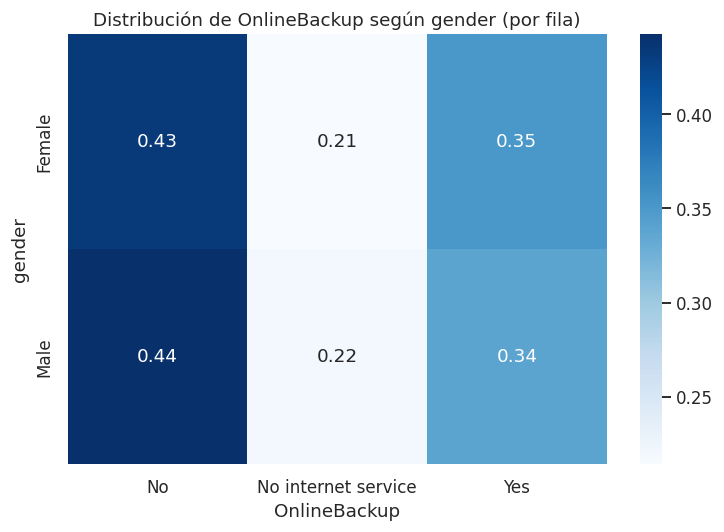

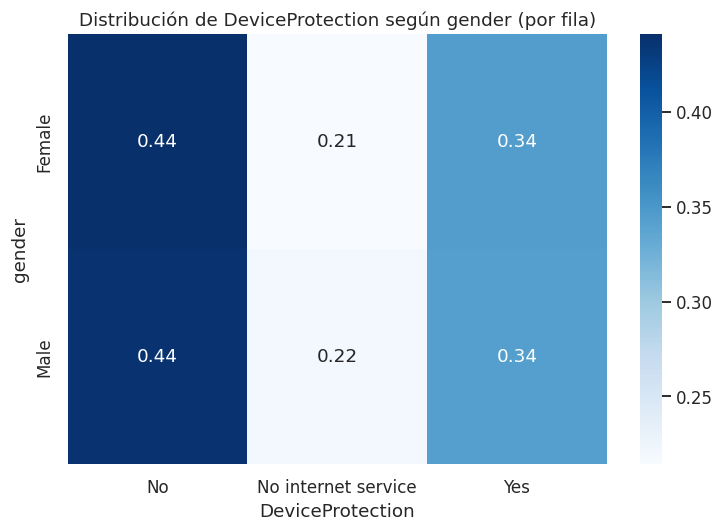

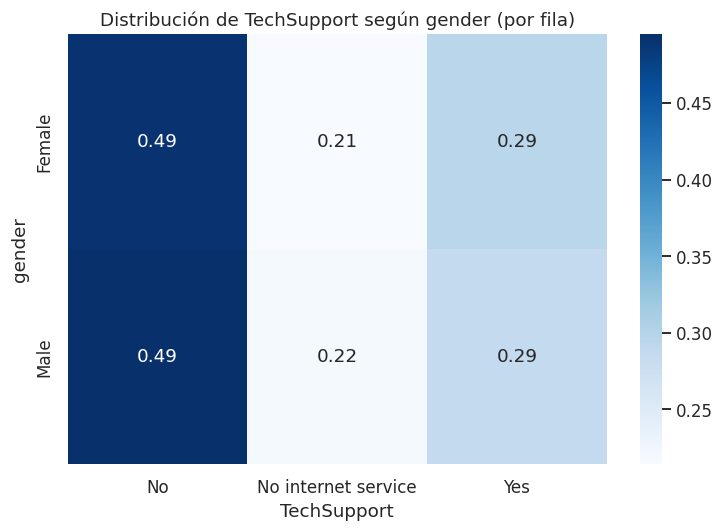

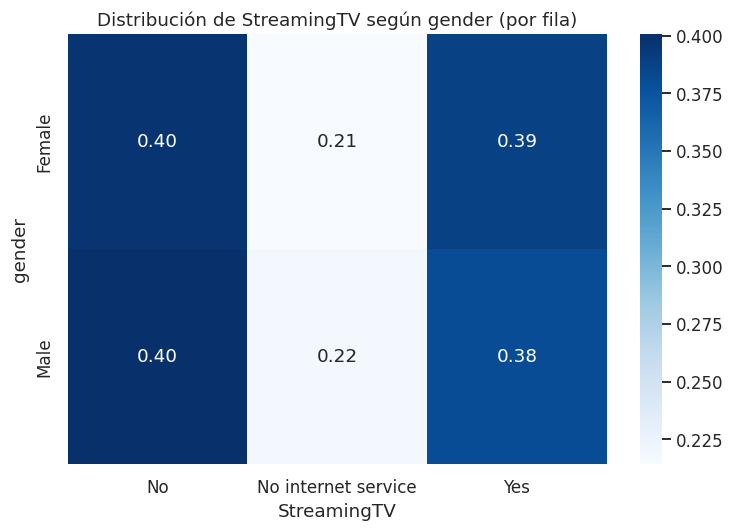

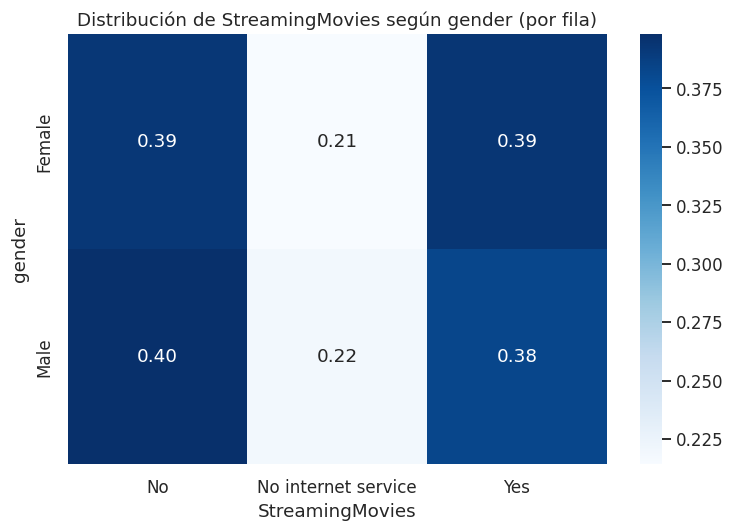

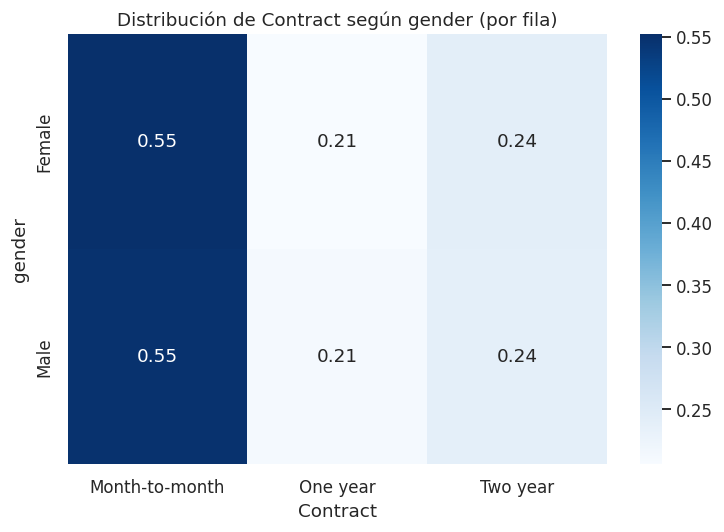

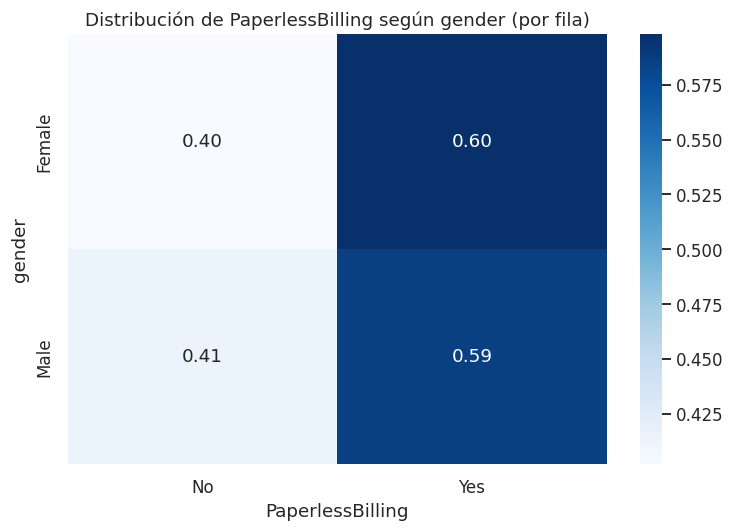

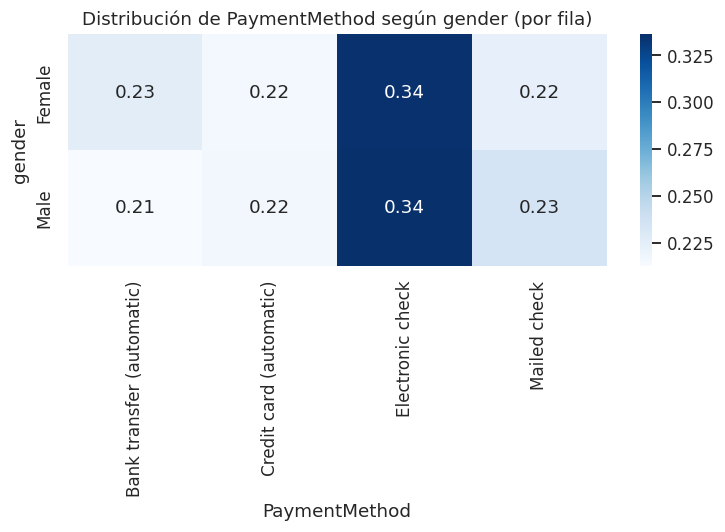

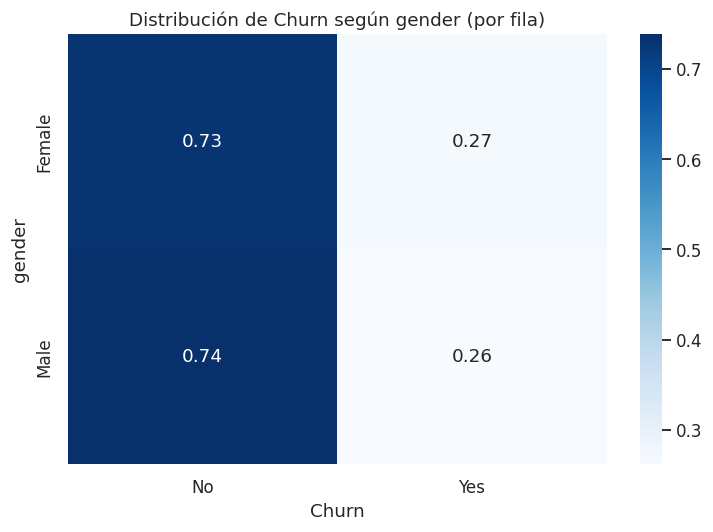

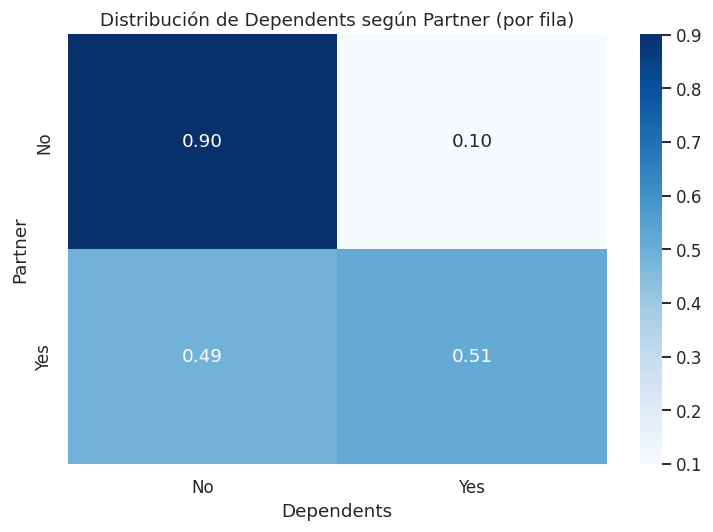

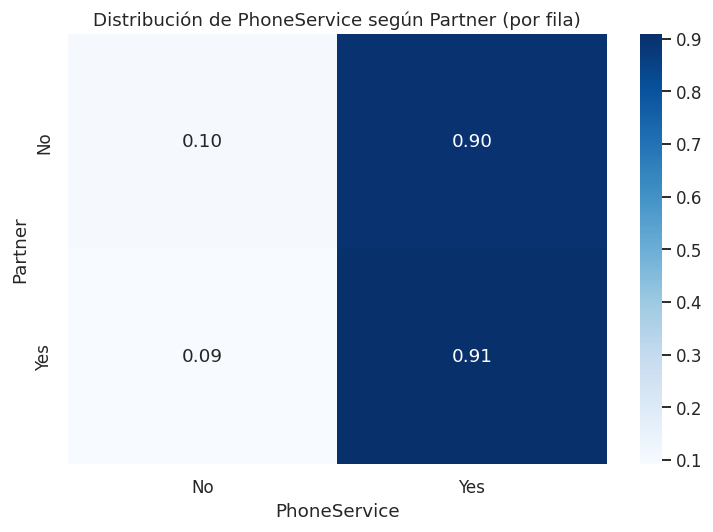

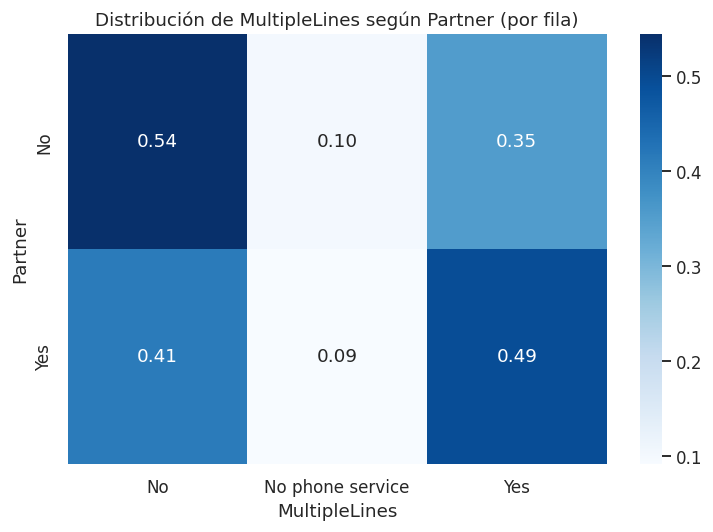

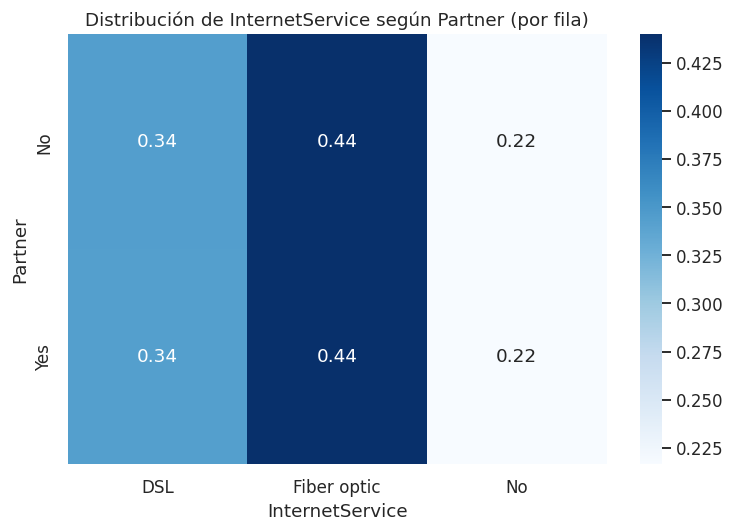

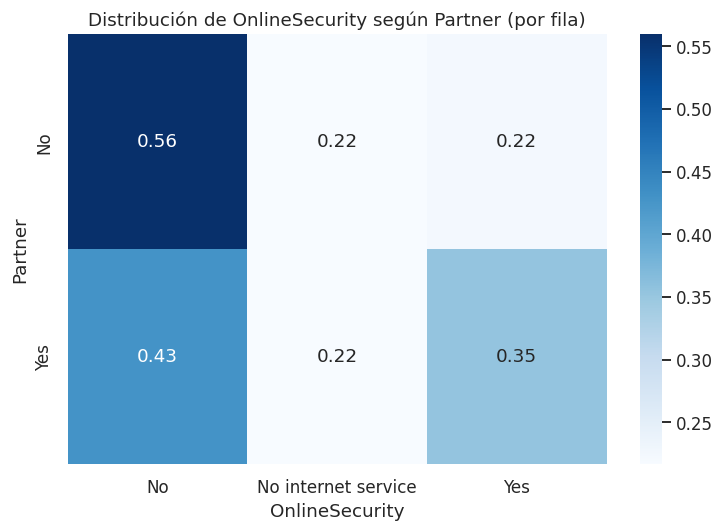

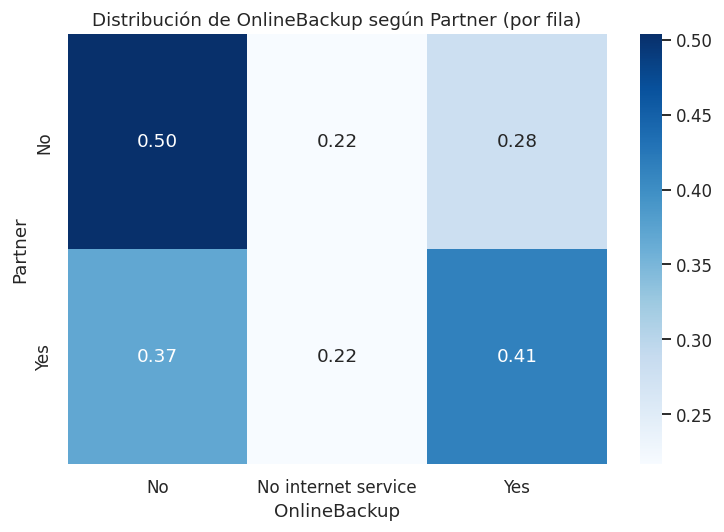

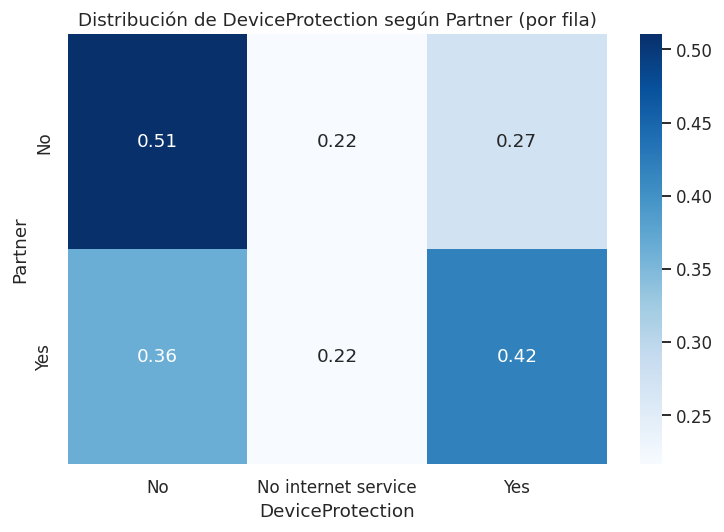

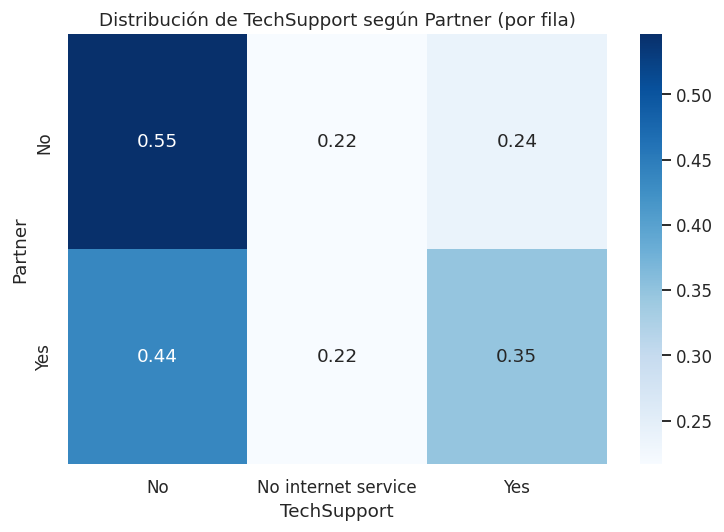

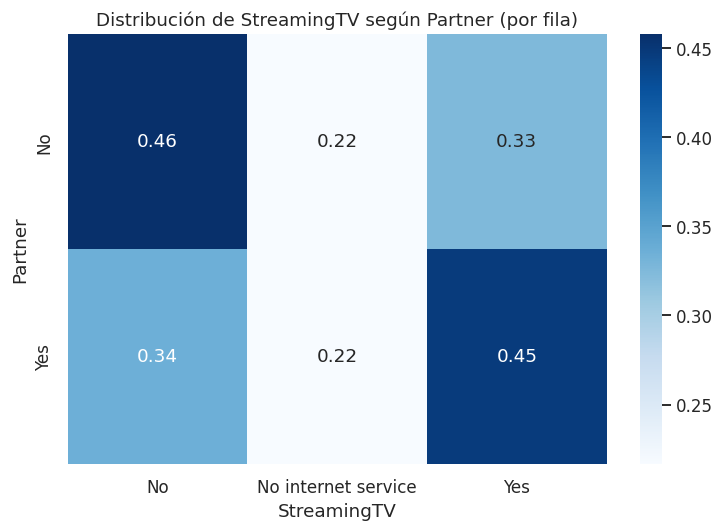

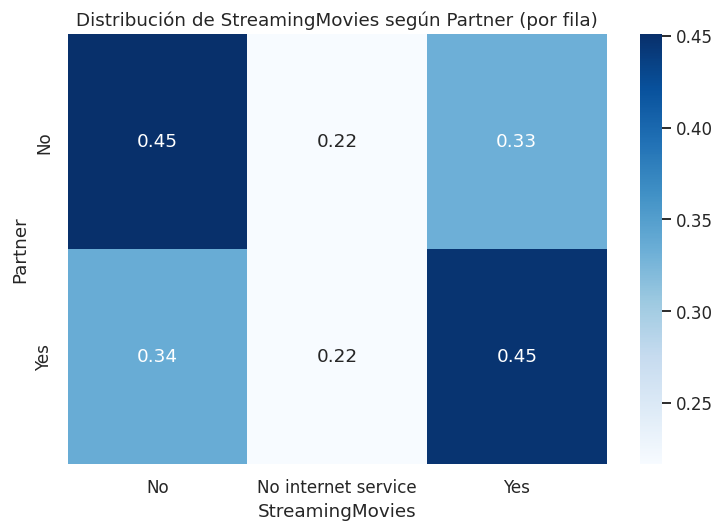

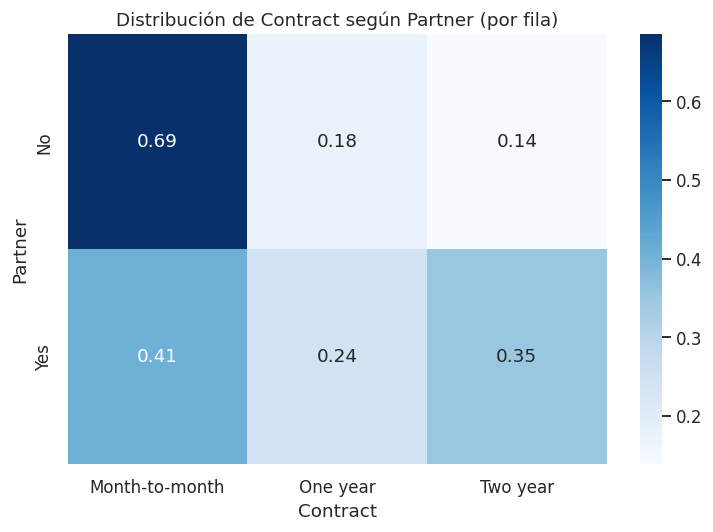

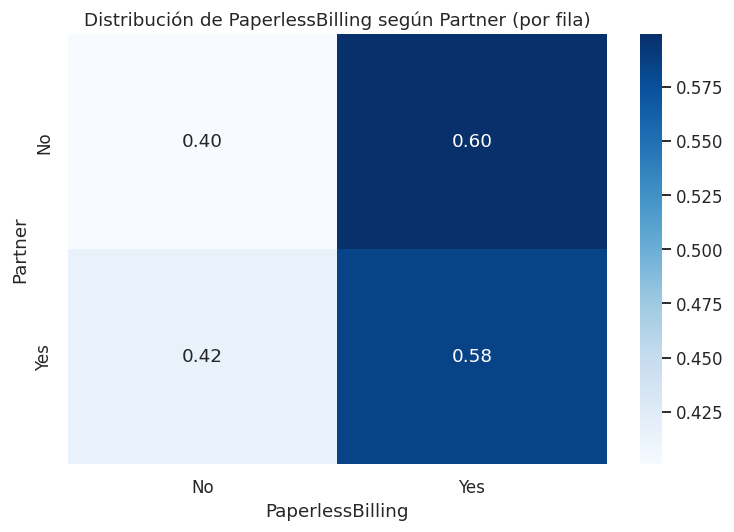

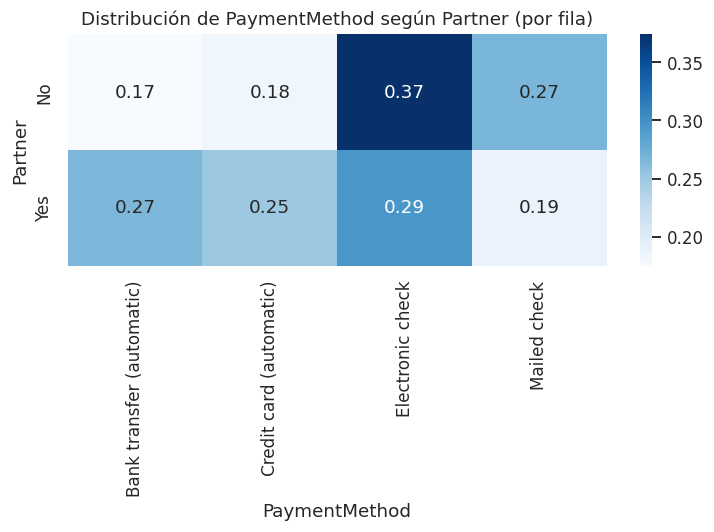

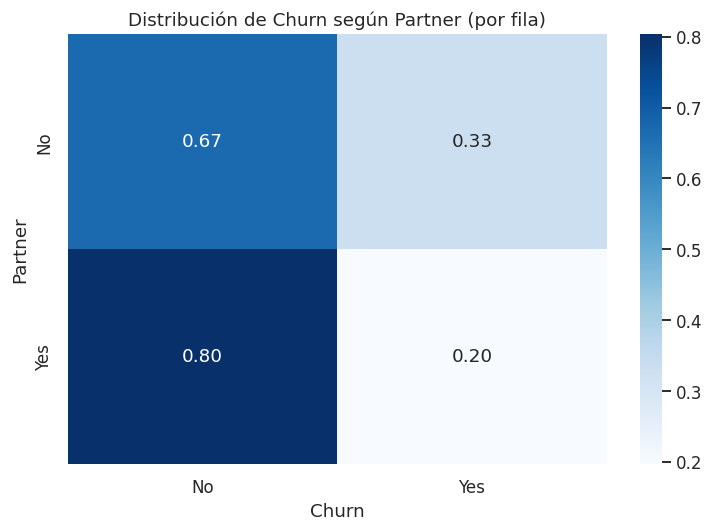

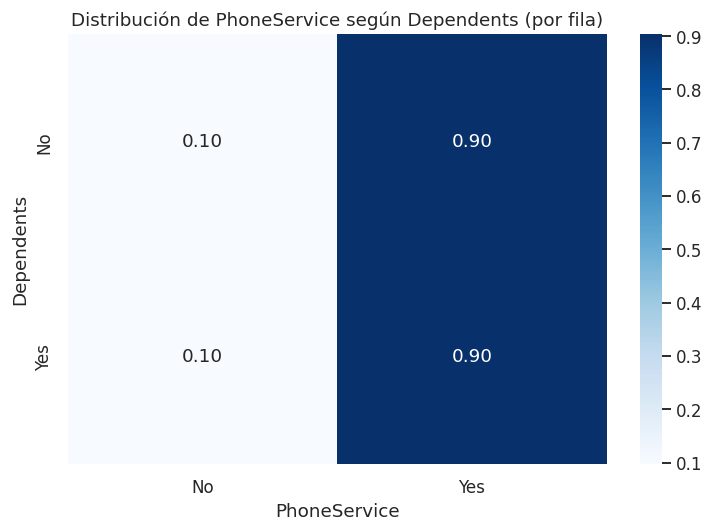

In [86]:
# Categórica vs. categórica: tablas de contingencia y heatmaps
cat_cat_pairs = list(combinations(categorical_cols, 2))
plotted = 0
for col_a, col_b in cat_cat_pairs:
    if plotted >= MAX_BIVARIATE_PLOTS:
        break
    a = analysis_df[col_a].astype("string").fillna("<Missing>")
    b = analysis_df[col_b].astype("string").fillna("<Missing>")
    top_a = a.value_counts().head(MAX_CATEGORIES).index
    top_b = b.value_counts().head(MAX_CATEGORIES).index
    mask = a.isin(top_a) & b.isin(top_b)
    if mask.sum() == 0:
        continue
    table = pd.crosstab(a[mask], b[mask], normalize="index")
    if table.empty:
        continue
    plt.figure(figsize=(max(7, min(13, table.shape[1] * 0.65)), max(5, min(10, table.shape[0] * 0.45))))
    sns.heatmap(table, cmap="Blues", annot=table.size <= 100, fmt=".2f")
    plt.title(f"Distribución de {col_b} según {col_a} (por fila)")
    plt.xlabel(col_b)
    plt.ylabel(col_a)
    plt.tight_layout()
    plt.show()
    plotted += 1

if not plotted:
    print("No se encontraron pares categórica-categórica para graficar.")

In [87]:
# Relaciones temporales: evolución de variables numéricas y categorías frecuentes
plots_done = 0
for date_col in datetime_cols:
    freq = choose_time_frequency(analysis_df[date_col])

    for num_col in numeric_cols:
        if plots_done >= MAX_DATETIME_PLOTS:
            break
        temp = analysis_df[[date_col, num_col]].dropna().copy()
        if temp.empty:
            continue
        temp["_period"] = temp[date_col].dt.to_period(freq)
        trend = temp.groupby("_period")[num_col].mean().sort_index()
        if len(trend) < 2:
            continue
        plt.figure(figsize=(12, 4))
        plt.plot(trend.index.astype(str), trend.values, marker="o")
        plt.title(f"Promedio de {num_col} a lo largo del tiempo ({date_col})")
        plt.xlabel("Período")
        plt.ylabel(f"Promedio de {num_col}")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
        plots_done += 1

    for cat_col in categorical_cols:
        if plots_done >= MAX_DATETIME_PLOTS:
            break
        temp = analysis_df[[date_col, cat_col]].dropna().copy()
        if temp.empty:
            continue
        temp["_period"] = temp[date_col].dt.to_period(freq).astype(str)
        temp["_category"] = temp[cat_col].astype("string")
        top_categories = temp["_category"].value_counts().head(min(5, MAX_CATEGORIES)).index
        counts = pd.crosstab(temp["_period"], temp["_category"])
        counts = counts.reindex(columns=top_categories, fill_value=0)
        if counts.empty:
            continue
        counts.plot(figsize=(12, 4), marker="o")
        plt.title(f"Frecuencia de categorías de {cat_col} a lo largo del tiempo ({date_col})")
        plt.xlabel("Período")
        plt.ylabel("Cantidad de registros")
        plt.xticks(rotation=45)
        plt.legend(title=cat_col, bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout()
        plt.show()
        plots_done += 1

    if plots_done >= MAX_DATETIME_PLOTS:
        break

if not datetime_cols:
    print("No se detectaron variables temporales para analizar relaciones a lo largo del tiempo.")
elif plots_done >= MAX_DATETIME_PLOTS:
    print(f"Se alcanzó el límite de {MAX_DATETIME_PLOTS} gráficos temporales.")

No se detectaron variables temporales para analizar relaciones a lo largo del tiempo.


## 8. Análisis de la variable objetivo (opcional)

Si `TARGET` está definido, se intenta determinar si el problema es de clasificación o regresión. Una variable numérica entera con pocas clases puede tratarse como clasificación; revisá el diagnóstico automático si el contexto del problema indica otra cosa.

In [48]:
target_type = None
if TARGET is None:
    print("TARGET = None. Se omite el análisis supervisado.")
else:
    target_series = analysis_df[TARGET]
    target_nunique = safe_nunique(target_series)
    is_target_numeric = pd.api.types.is_numeric_dtype(target_series)
    is_target_bool = pd.api.types.is_bool_dtype(target_series)
    target_non_null = target_series.dropna()
    integer_like_target = (
        is_target_numeric and not target_non_null.empty
        and np.allclose(target_non_null.to_numpy(dtype=float), np.round(target_non_null.to_numpy(dtype=float)))
    )

    if is_target_bool or not is_target_numeric:
        target_type = "classification"
    elif integer_like_target and target_nunique <= TARGET_CLASSIFICATION_MAX_CLASSES:
        target_type = "classification"
    else:
        target_type = "regression"

    print(f"Target: {TARGET}")
    print(f"Tipo detectado: {'Clasificación' if target_type == 'classification' else 'Regresión'}")
    print(f"Valores únicos: {target_nunique:,}")
    print(f"Valores faltantes: {target_series.isna().sum():,} ({target_series.isna().mean():.2%})")

Target: Churn
Tipo detectado: Clasificación
Valores únicos: 2
Valores faltantes: 0 (0.00%)


,count,percentage
Churn,,
No,5174,73.463
Yes,1869,26.537


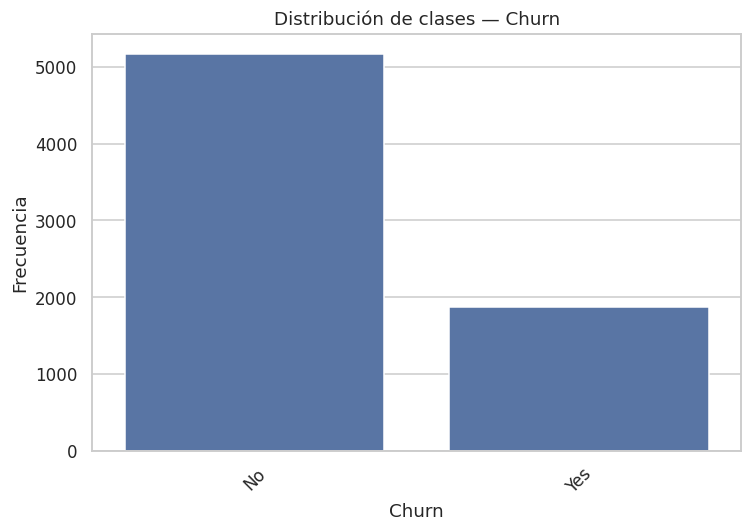

Relación entre clase mayoritaria y minoritaria: 2.77:1
No se observa un desbalance extremo según este criterio orientativo.


In [49]:
if TARGET is not None and target_type == "classification":
    target_counts = analysis_df[TARGET].dropna().astype("string").value_counts()
    target_summary = pd.DataFrame({
        "count": target_counts,
        "percentage": 100 * target_counts / max(len(analysis_df), 1),
    })
    display(target_summary)

    plt.figure(figsize=(max(7, min(12, len(target_counts) * 0.6)), 5))
    sns.barplot(x=target_counts.index.astype(str), y=target_counts.values, color=sns.color_palette()[0])
    plt.title(f"Distribución de clases — {TARGET}")
    plt.xlabel(TARGET)
    plt.ylabel("Frecuencia")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    class_shares = target_counts / target_counts.sum()
    imbalance_ratio = class_shares.max() / max(class_shares.min(), 1e-12)
    print(f"Relación entre clase mayoritaria y minoritaria: {imbalance_ratio:.2f}:1")
    if imbalance_ratio >= 3 or class_shares.min() < 0.10:
        print("⚠️ Posible desbalance de clases. Evaluar métricas y estrategias adecuadas; no aplicar cambios automáticamente.")
    else:
        print("No se observa un desbalance extremo según este criterio orientativo.")

elif TARGET is not None and target_type == "regression":
    display(analysis_df[TARGET].describe().to_frame("value"))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    sns.histplot(analysis_df[TARGET].dropna(), kde=True, color=sns.color_palette()[0], ax=axes[0])
    axes[0].set_title(f"Distribución del target — {TARGET}")
    sns.boxplot(x=analysis_df[TARGET], ax=axes[1])
    axes[1].set_title(f"Boxplot del target — {TARGET}")
    plt.tight_layout()
    plt.show()

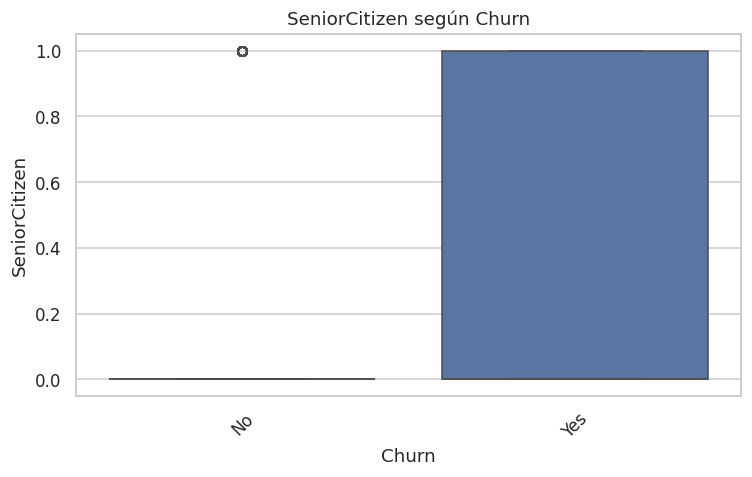

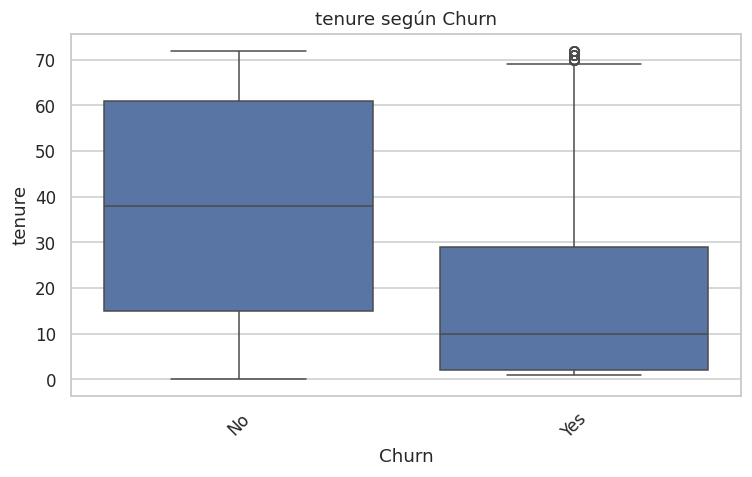

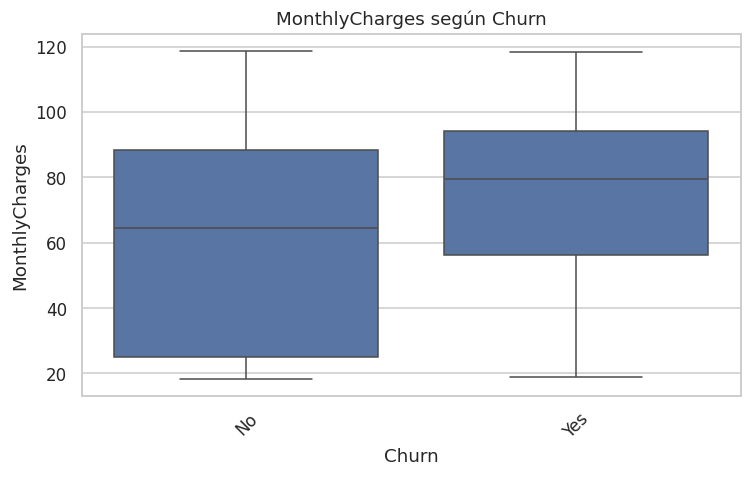

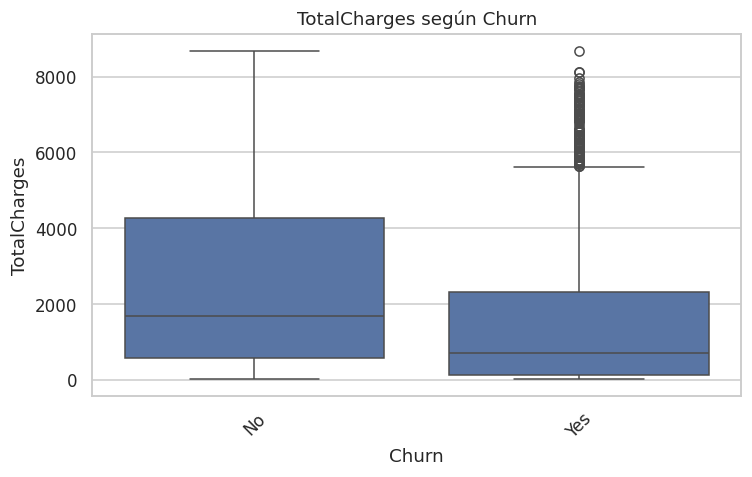

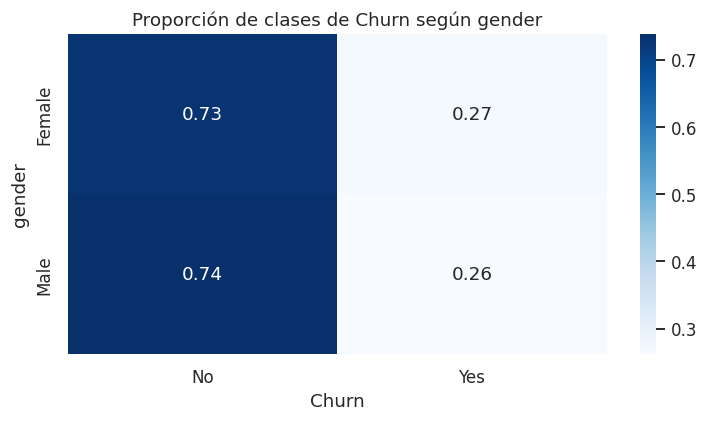

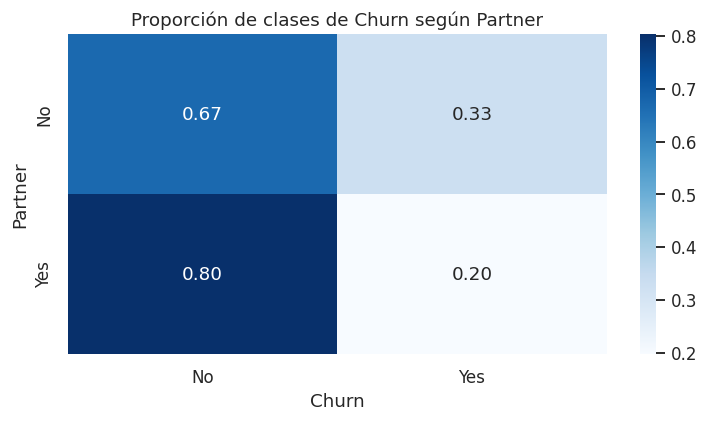

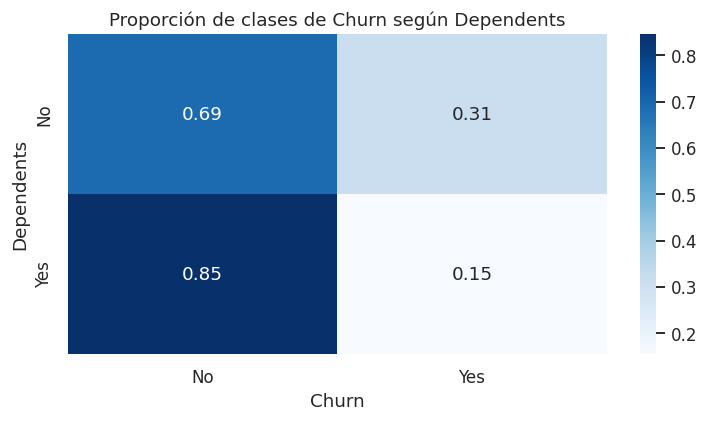

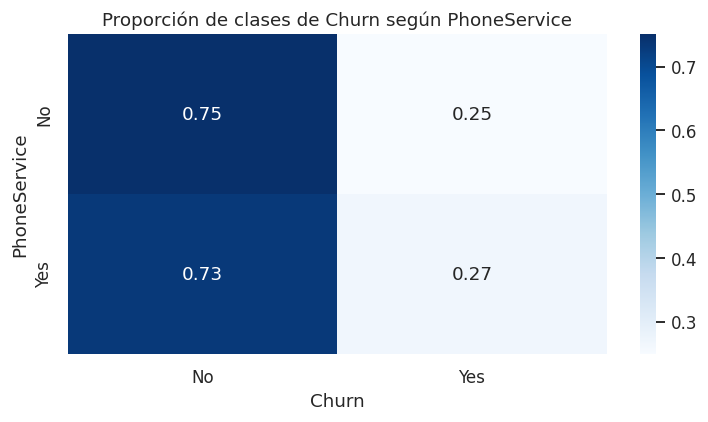

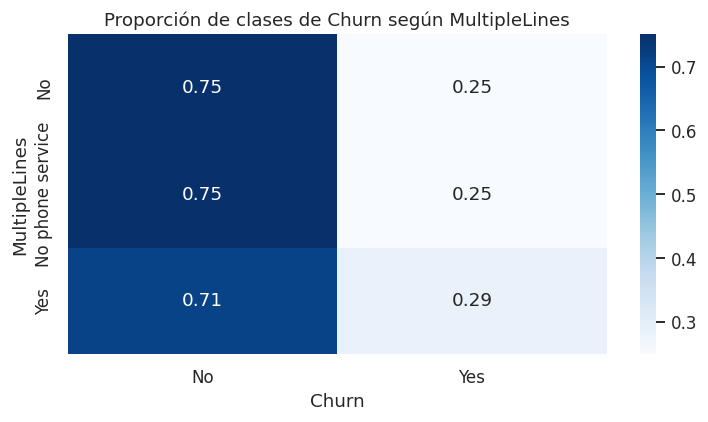

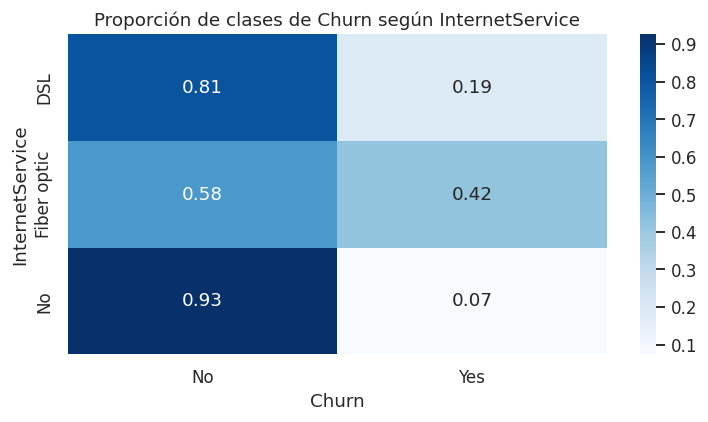

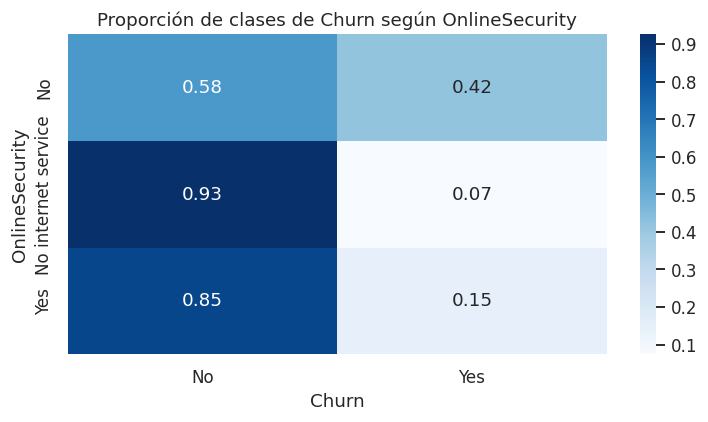

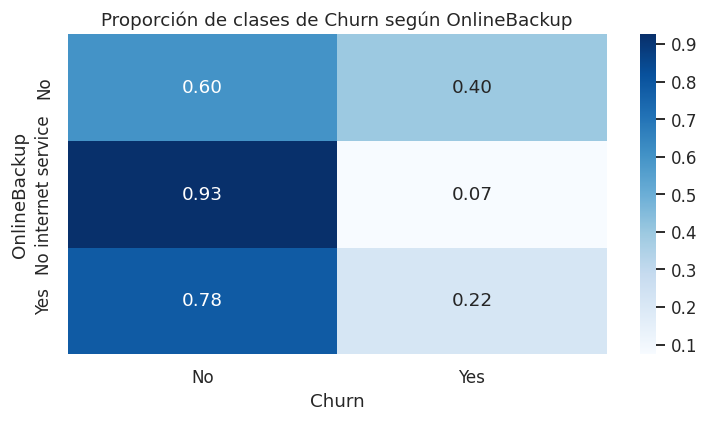

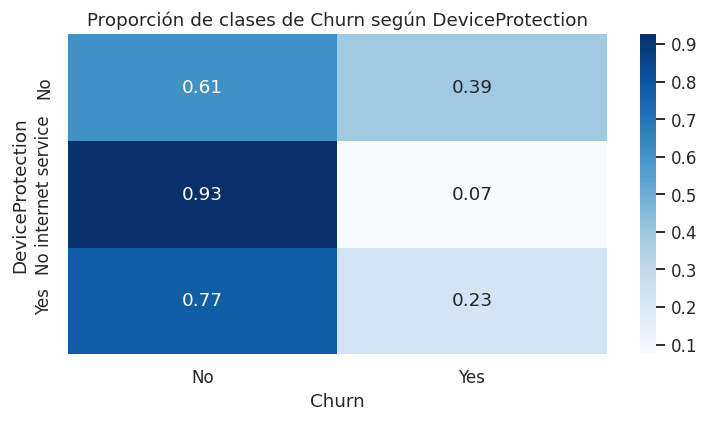

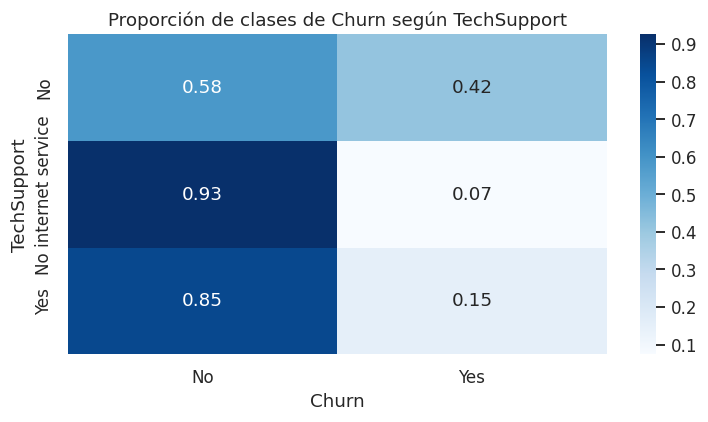

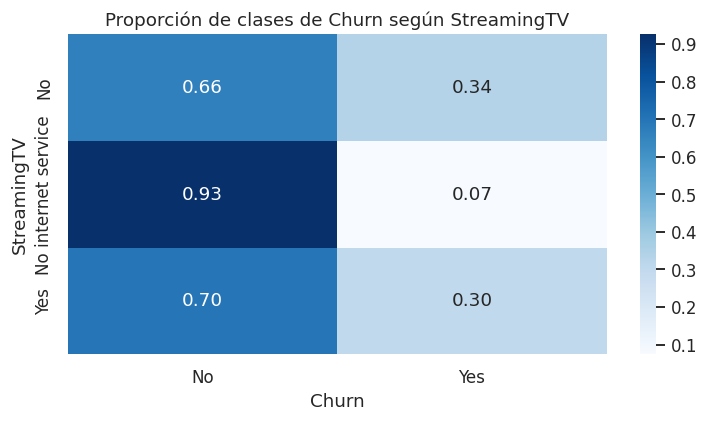

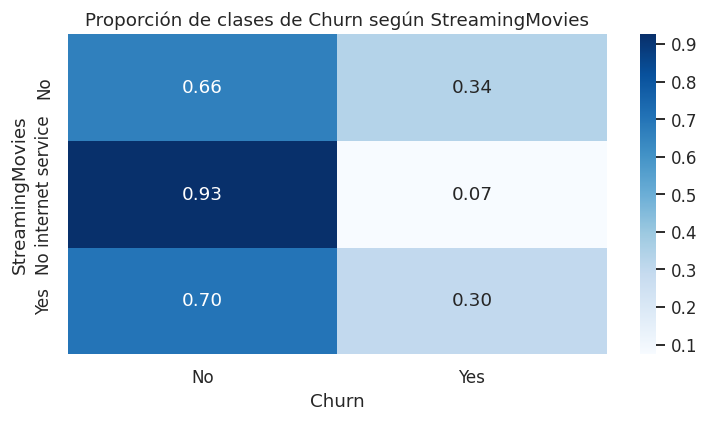

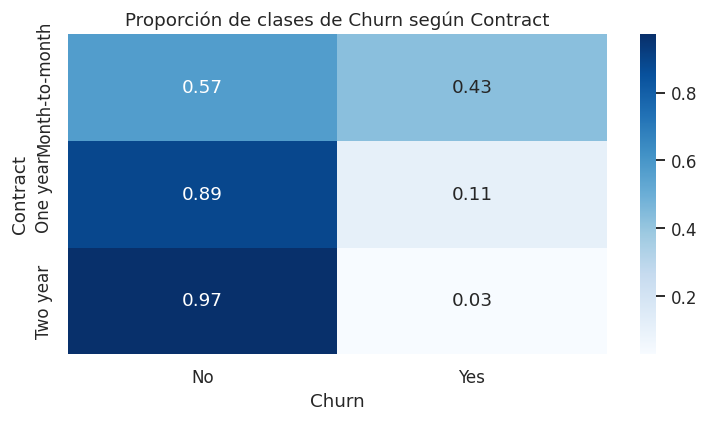

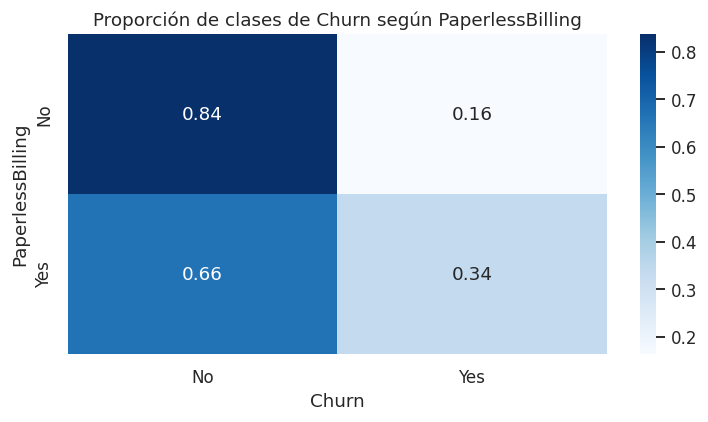

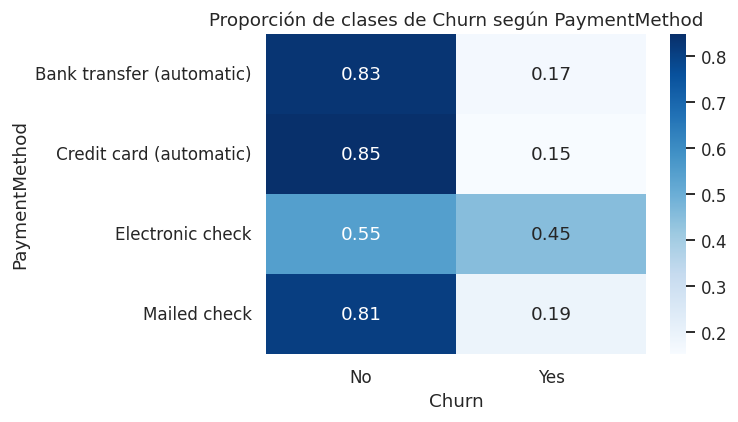

In [88]:
# Relación de las features con el target
if TARGET is not None and target_type == "classification":
    plots_done = 0
    for feature in numeric_cols:
        if feature == TARGET or plots_done >= MAX_BIVARIATE_PLOTS:
            continue
        subset = analysis_df[[TARGET, feature]].dropna()
        if subset.empty:
            continue
        plt.figure(figsize=(max(7, min(12, subset[TARGET].nunique() * 0.65)), 4.5))
        sns.boxplot(data=subset, x=TARGET, y=feature)
        plt.title(f"{feature} según {TARGET}")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
        plots_done += 1

    for feature in categorical_cols:
        if feature == TARGET or plots_done >= MAX_BIVARIATE_PLOTS:
            continue
        feature_values = analysis_df[feature].astype("string").fillna("<Missing>")
        target_values = analysis_df[TARGET].astype("string").fillna("<Missing>")
        top_features = feature_values.value_counts().head(MAX_CATEGORIES).index
        mask = feature_values.isin(top_features)
        table = pd.crosstab(feature_values[mask], target_values[mask], normalize="index")
        if table.empty:
            continue
        plt.figure(figsize=(max(7, min(12, table.shape[1] * 0.7)), max(4, min(9, table.shape[0] * 0.4))))
        sns.heatmap(table, cmap="Blues", annot=table.size <= 100, fmt=".2f")
        plt.title(f"Proporción de clases de {TARGET} según {feature}")
        plt.xlabel(TARGET)
        plt.ylabel(feature)
        plt.tight_layout()
        plt.show()
        plots_done += 1

elif TARGET is not None and target_type == "regression":
    if numeric_cols:
        target_correlations = analysis_df[numeric_cols].corr(method="spearman")[TARGET].drop(TARGET, errors="ignore").sort_values(key=lambda values: values.abs(), ascending=False)
        print("Correlaciones de Spearman con el target")
        display(target_correlations.to_frame("spearman_correlation"))

    plots_done = 0
    for feature in categorical_cols:
        if feature == TARGET or plots_done >= MAX_BIVARIATE_PLOTS:
            continue
        subset = analysis_df[[feature, TARGET]].dropna().copy()
        top_categories = subset[feature].astype("string").value_counts().head(MAX_CATEGORIES).index
        subset = subset[subset[feature].astype("string").isin(top_categories)]
        if subset[feature].nunique() < 2:
            continue
        plt.figure(figsize=(max(7, min(12, subset[feature].nunique() * 0.65)), 4.5))
        sns.boxplot(data=subset, x=feature, y=TARGET)
        plt.title(f"{TARGET} según {feature}")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
        plots_done += 1

## 9. Outliers y redundancia entre variables

El método IQR señala observaciones fuera de los límites `Q1 - 1.5 × IQR` y `Q3 + 1.5 × IQR`. Es una alerta exploratoria: un outlier no es necesariamente un error y no debe eliminarse sin analizar el contexto.

In [51]:
outlier_rows = []
for col in numeric_cols:
    values = analysis_df[col].dropna()
    if len(values) < 4 or values.nunique() < 2:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr == 0:
        lower_bound, upper_bound = q1, q3
    else:
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
    outlier_count = int(((values < lower_bound) | (values > upper_bound)).sum())
    outlier_rows.append({
        "feature": col,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_pct": 100 * outlier_count / len(values),
    })

outlier_report = pd.DataFrame(outlier_rows)
if not outlier_report.empty:
    display(outlier_report.sort_values("outlier_pct", ascending=False))
else:
    print("No hay variables numéricas suficientes para calcular outliers mediante IQR.")

,feature,lower_bound,upper_bound,outlier_count,outlier_pct
0,SeniorCitizen,0.000,0.000,1142,16.215
1,tenure,-60.000,124.000,0,0.000
2,MonthlyCharges,-46.025,171.375,0,0.000
3,TotalCharges,"-4,688.481","8,884.669",0,0.000


In [52]:
# Pares de variables con correlación elevada (posible redundancia)
if len(numeric_cols) >= 2:
    corr_for_pairs = analysis_df[numeric_cols].corr(method="spearman").abs()
    upper_triangle = corr_for_pairs.where(np.triu(np.ones(corr_for_pairs.shape), k=1).astype(bool))
    high_corr_pairs = (
        upper_triangle.stack()
        .reset_index()
        .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "abs_spearman"})
    )
    high_corr_pairs = high_corr_pairs[high_corr_pairs["abs_spearman"] >= 0.90]
    high_corr_pairs = high_corr_pairs.sort_values("abs_spearman", ascending=False)
    if high_corr_pairs.empty:
        print("No se encontraron pares con |Spearman| >= 0.90.")
    else:
        display(high_corr_pairs)
        print("⚠️ Correlación elevada puede indicar redundancia, pero no implica que una variable deba eliminarse automáticamente.")
else:
    print("Se necesitan al menos dos variables numéricas para revisar correlaciones elevadas.")

No se encontraron pares con |Spearman| >= 0.90.


## 10. Alertas orientativas: leakage y oportunidades de Feature Engineering

Estas reglas son heurísticas para orientar la revisión. No prueban que exista data leakage ni determinan qué transformaciones conviene aplicar: la decisión depende del problema y del momento en que las variables estarían disponibles en producción.

In [53]:
# Alertas simples de posible leakage respecto del target
if TARGET is None:
    print("No se analiza posible leakage porque TARGET = None.")
else:
    leakage_rows = []
    target_values = analysis_df[TARGET]
    for feature in analysis_df.columns:
        if feature == TARGET:
            continue
        feature_values = analysis_df[feature]
        valid_mask = target_values.notna() & feature_values.notna()
        if valid_mask.sum() == 0:
            continue

        equality_rate = np.nan
        try:
            equality_rate = (feature_values[valid_mask].astype(str) == target_values[valid_mask].astype(str)).mean()
        except Exception:
            pass

        corr_value = np.nan
        if (pd.api.types.is_numeric_dtype(feature_values)
                and pd.api.types.is_numeric_dtype(target_values)):
            corr_value = feature_values.corr(target_values)

        name_hint = str(TARGET).lower() in str(feature).lower()
        if name_hint or (pd.notna(equality_rate) and equality_rate >= 0.95) or (pd.notna(corr_value) and abs(corr_value) >= 0.98):
            leakage_rows.append({
                "feature": feature,
                "name_similarity_hint": name_hint,
                "equality_rate": equality_rate,
                "pearson_correlation": corr_value,
            })

    if leakage_rows:
        display(pd.DataFrame(leakage_rows).sort_values("equality_rate", ascending=False, na_position="last"))
        print("⚠️ Revisá si estas variables contienen información del target o información que no estaría disponible al momento de predecir.")
    else:
        print("No se detectaron alertas simples de posible leakage. Esto no garantiza que no exista.")

No se detectaron alertas simples de posible leakage. Esto no garantiza que no exista.


In [55]:
# Ideas iniciales para Feature Engineering según el perfil observado
engineering_ideas = []

for col in datetime_cols:
    engineering_ideas.append({
        "feature": col,
        "observation": "Variable temporal detectada",
        "possible_idea": "Evaluar extraer año, mes, día de semana, hora, antigüedad o tiempo transcurrido, según el problema.",
    })

if numeric_cols:
    skew_values = analysis_df[numeric_cols].skew(numeric_only=True)
    for col, skew_value in skew_values.items():
        if pd.notna(skew_value) and abs(skew_value) > 1:
            idea = "Evaluar transformación log1p si los valores son no negativos" if analysis_df[col].dropna().ge(0).all() else "Revisar asimetría; considerar transformaciones robustas según el dominio"
            engineering_ideas.append({
                "feature": col,
                "observation": f"Asimetría elevada (skew={skew_value:.2f})",
                "possible_idea": idea,
            })

for col in categorical_cols:
    n_unique = safe_nunique(analysis_df[col])
    if n_unique > MAX_CATEGORIES:
        engineering_ideas.append({
            "feature": col,
            "observation": f"Cardinalidad relativamente alta ({n_unique} categorías)",
            "possible_idea": "Evaluar agrupación de categorías poco frecuentes u otro encoding apropiado, sin perder información relevante.",
        })

if engineering_ideas:
    display(pd.DataFrame(engineering_ideas))
else:
    print("No surgieron sugerencias automáticas con las reglas actuales.")

,feature,observation,possible_idea
0,SeniorCitizen,Asimetría elevada (skew=1.83),Evaluar transformación log1p si los valores so...
1,customerID,Cardinalidad relativamente alta (7043 categorías),Evaluar agrupación de categorías poco frecuent...


## 11. Resumen final del EDA

Este resumen reúne los principales indicadores para facilitar la revisión antes de pasar a limpieza, preprocessing o modelado.

In [56]:
summary = {
    "rows": len(df),
    "columns": df.shape[1],
    "numeric_features": len(numeric_cols),
    "categorical_features": len(categorical_cols),
    "datetime_features": len(datetime_cols),
    "duplicate_rows": int(df.duplicated().sum()),
    "columns_with_missing_values": int(df.isna().any().sum()),
    "total_missing_values": int(df.isna().sum().sum()),
    "constant_columns": int(quality_report["constant"].sum()),
    "possible_identifier_columns": int(quality_report["possible_id"].sum()),
}
if TARGET is not None:
    summary["target"] = TARGET
    summary["target_type_detected"] = target_type
    summary["target_unique_values"] = safe_nunique(analysis_df[TARGET])

display(pd.Series(summary, name="value").to_frame())

print("\nPróximos pasos sugeridos:")
print("1. Revisar las alertas de calidad de datos y validar identificadores.")
print("2. Entender el origen y significado de los valores faltantes y outliers.")
print("3. Confirmar que las columnas temporales y numéricas detectadas estén bien clasificadas.")
print("4. Definir una estrategia de preprocessing dentro de una pipeline separada.")
print("5. Si hay target, revisar desbalance, leakage y métricas de evaluación apropiadas.")

,value
rows,7043
columns,21
numeric_features,4
categorical_features,17
datetime_features,0
duplicate_rows,0
columns_with_missing_values,0
total_missing_values,0
constant_columns,0
possible_identifier_columns,1



Próximos pasos sugeridos:
1. Revisar las alertas de calidad de datos y validar identificadores.
2. Entender el origen y significado de los valores faltantes y outliers.
3. Confirmar que las columnas temporales y numéricas detectadas estén bien clasificadas.
4. Definir una estrategia de preprocessing dentro de una pipeline separada.
5. Si hay target, revisar desbalance, leakage y métricas de evaluación apropiadas.


---

## Notas y posibles extensiones

- **Datasets grandes:** reducí `MAX_SAMPLE`, `MAX_PAIR_PLOTS` o `MAX_BIVARIATE_PLOTS`.
- **Datasets muy anchos:** reducí `MAX_CORR_FEATURES` para mantener legibles los heatmaps.
- **Fechas no detectadas:** convertí explícitamente la columna en la sección de carga o ajustá `DATETIME_PARSE_THRESHOLD`.
- **Códigos numéricos:** revisá si deben permanecer como texto/categoría, especialmente cuando tienen ceros a la izquierda.
- **Clasificación vs. regresión:** la detección de `TARGET` es una heurística. Podés forzar la interpretación manualmente si conocés el problema.
- **Feature importance:** conviene agregarla en una etapa posterior, una vez definido el preprocessing y una validación adecuada, para evitar interpretaciones engañosas.

**La plantilla no reemplaza el criterio analítico:** sus alertas y gráficos sirven para formular preguntas y orientar decisiones, no para tomar decisiones automáticas sobre los datos.